# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [1]:
#Installing the libraries with the specified versions
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 requests==2.32.4 huggingface_hub==0.34.0 -q

**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [2]:
import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# For splitting the dataset
from sklearn.model_selection import train_test_split

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor

# Libraries to get different metric scores
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

# To create the pipeline
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,Pipeline

# To tune different models and standardize
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder

# To serialize the model
import joblib

# os related functionalities
import os

# API request
import requests

# for hugging face space authentication to upload files
from huggingface_hub import login, HfApi

# **Loading the dataset**

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
kart = pd.read_csv("/content/drive/MyDrive/AIML/Project7/SuperKart.csv")

In [5]:
data = kart.copy()

# **Data Overview**

### Preview of the dataset

In [6]:
#View the first 5 rows of the dataset
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [7]:
#View the last 5 rows of the dataset
data.tail()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
8758,NC7546,14.80,No Sugar,0.016,Health and Hygiene,140.53,OUT004,2009,Medium,Tier 2,Supermarket Type2,3806.53
8759,NC584,14.06,No Sugar,0.142,Household,144.51,OUT004,2009,Medium,Tier 2,Supermarket Type2,5020.74
8760,NC2471,13.48,No Sugar,0.017,Health and Hygiene,88.58,OUT001,1987,High,Tier 2,Supermarket Type1,2443.42
8761,NC7187,13.89,No Sugar,0.193,Household,168.44,OUT001,1987,High,Tier 2,Supermarket Type1,4171.82
8762,FD306,14.73,Low Sugar,0.177,Snack Foods,224.93,OUT002,1998,Small,Tier 3,Food Mart,2186.08


In [8]:
data.shape

(8763, 12)

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 821.7+ KB


**OBSERVATIONS**:

---

- There are 8763 records (rows) in the dataset, each with 12 features (columns)
- The type of the columns are float, int and object.



### Statistical details of the dataset

In [10]:
data.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,8763,8763,FD306,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,8763.0,NaN,NaN,NaN,12.653792,2.21732,4.0,11.15,12.66,14.18,22.0
Product_Sugar_Content,8763,4,Low Sugar,4885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,8763.0,NaN,NaN,NaN,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_Type,8763,16,Fruits and Vegetables,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,8763.0,NaN,NaN,NaN,147.032539,30.69411,31.0,126.16,146.74,167.585,266.0
Store_Id,8763,4,OUT004,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,8763.0,NaN,NaN,NaN,2002.032751,8.388381,1987.0,1998.0,2009.0,2009.0,2009.0
Store_Size,8763,3,Medium,6025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,8763,3,Tier 2,6262,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
data.duplicated().sum()

np.int64(0)

In [12]:
data.isnull().sum()

,0
Product_Id,0
Product_Weight,0
Product_Sugar_Content,0
Product_Allocated_Area,0
Product_Type,0
Product_MRP,0
Store_Id,0
Store_Establishment_Year,0
Store_Size,0
Store_Location_City_Type,0


In [13]:
data['Product_Type'].unique()

array(['Frozen Foods', 'Dairy', 'Canned', 'Baking Goods',
       'Health and Hygiene', 'Snack Foods', 'Meat', 'Household',
       'Hard Drinks', 'Fruits and Vegetables', 'Breads', 'Soft Drinks',
       'Breakfast', 'Others', 'Starchy Foods', 'Seafood'], dtype=object)

In [14]:
data['Store_Size'].unique()

array(['Medium', 'High', 'Small'], dtype=object)

In [15]:
data['Store_Location_City_Type'].unique()

array(['Tier 2', 'Tier 1', 'Tier 3'], dtype=object)

In [16]:
data['Store_Type'].unique()

array(['Supermarket Type2', 'Departmental Store', 'Supermarket Type1',
       'Food Mart'], dtype=object)

OBSERVATIONS:

- We have 8763 records in the dataset and the values for each of the columns are present.
- There are no duplicate values in the dataset
- There are no null values in the data set

- We can convert the column: Product_Sugar_Content, Store_Size, Store_Location_City_Type  into categorical columns

# **Exploratory Data Analysis (EDA)**

## Univariate Analysis

In [17]:
# function to plot a boxplot and a histogram along the same scale.

def histogram_boxplot(data, feature, figsize=(10, 5), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [18]:
numerical_cols= data.select_dtypes(include=['int64','float64']).columns

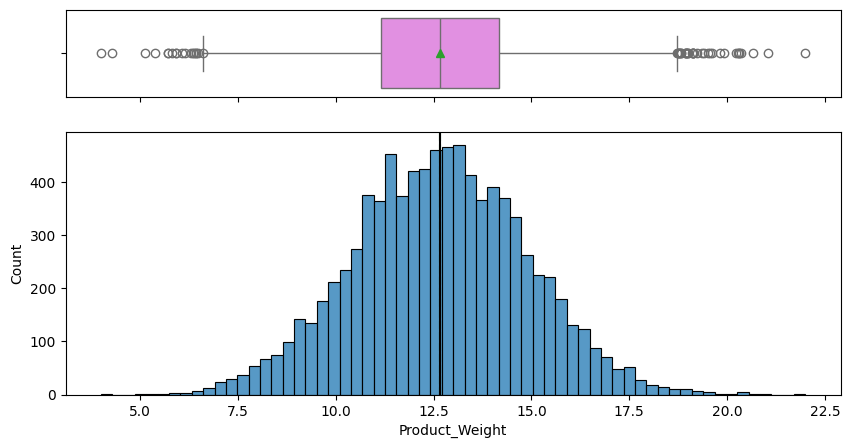

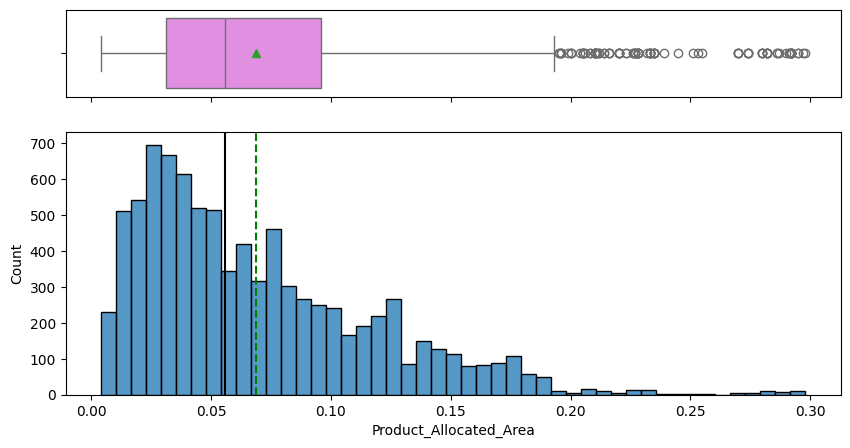

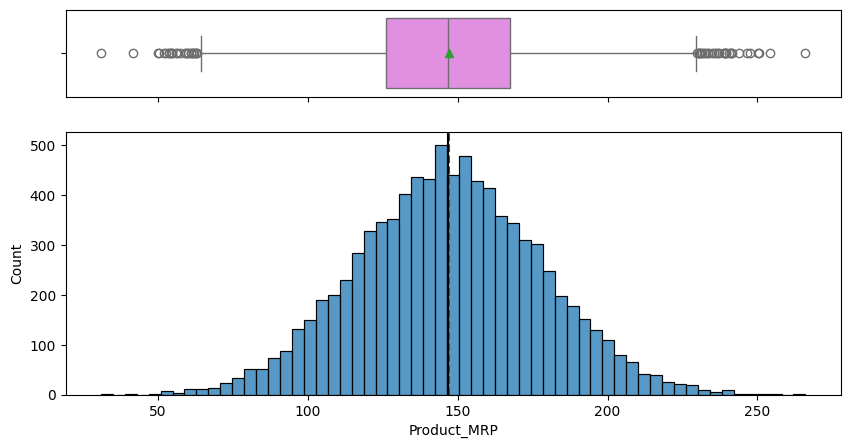

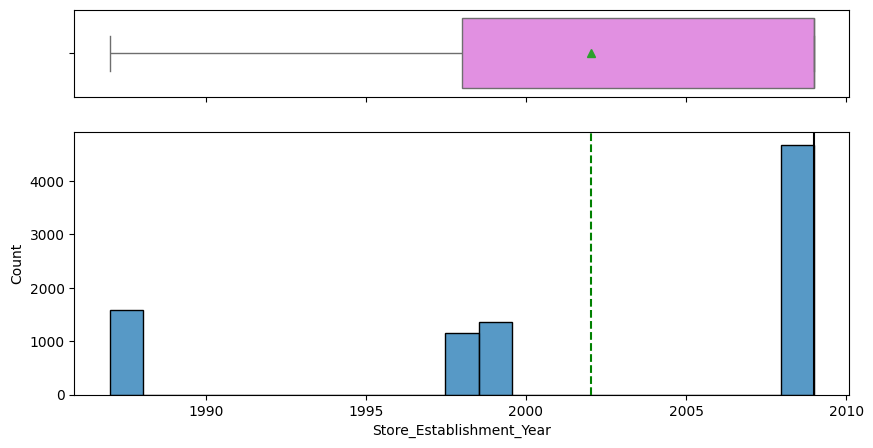

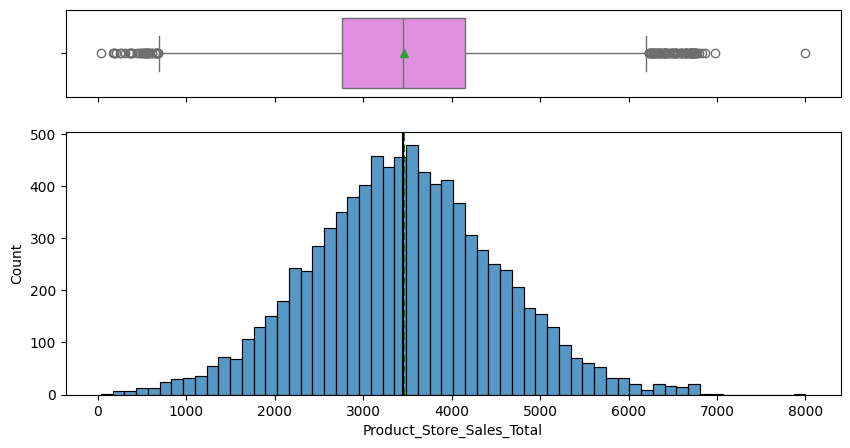

In [19]:
for col in numerical_cols:
  histogram_boxplot(data,col)
  plt.show()
  print("\n" * 5)

In [20]:
data['Store_Establishment_Year'].unique()

array([2009, 1999, 1987, 1998])

**OBSERVATIONS**:


---

- Based on the histogram and box plots,
1. Product Weight data is well balances with a mean of about 12.5. Based on the box plot, it has outliers.
2. Product Allocated Area has uneven distribution and is right skewed.The mean value is approx. 0.7
3. Product MRP is also an evenly distributed data range with values between 50-250 and mean at alightly less than 150. Although this feature also has outliers
4. Store Establishment Year graphs have interesting insight because seems like the dataset has only 4 values. Can convert this column to categorical.
5. Product Store Sales Total also seems to be a relatively evenly distributed graph with a mean value of 3500. Although it is not clear for what time range is this value for (Overall historic sales, last x years, last quarter or what).



### Bar Plots

In [21]:
# function to create labeled barplots
def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

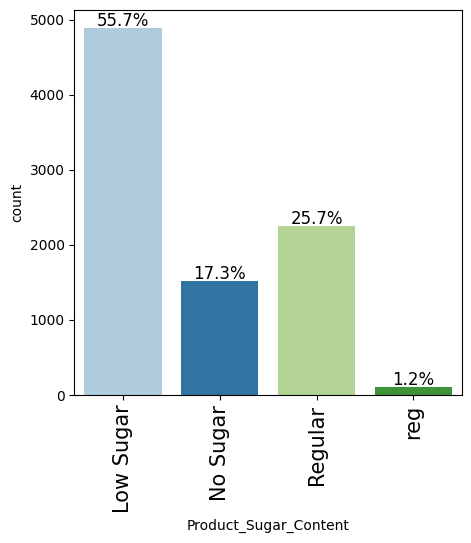

In [22]:
labeled_barplot(data, "Product_Sugar_Content", perc=True)

**OBSERVATIONS**:


---

- Based on the barplot for Product_Sugar_Content, more than 50% of product sales are from Low Sugar products
- Only 1.2% of sales are from products with "reg" sugar. Also it seems like Regular and reg must indicate the same value and can possibly be combined.


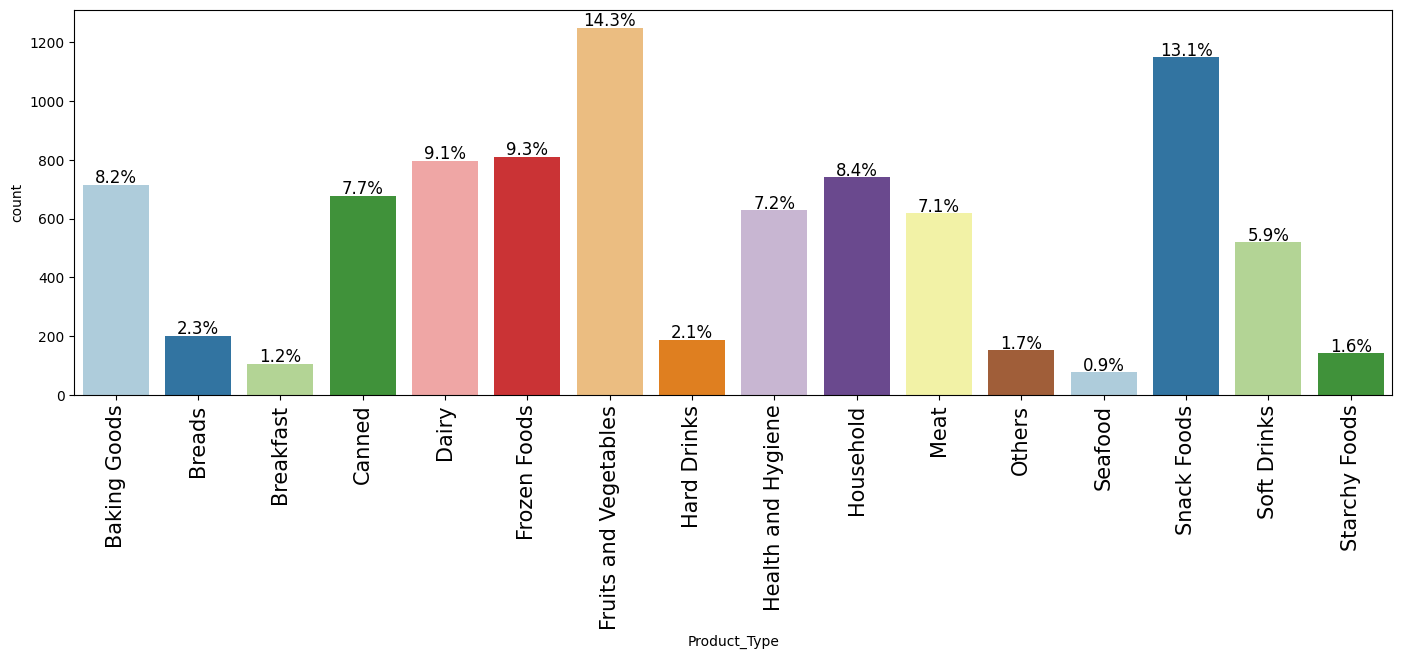

In [23]:
labeled_barplot(data, "Product_Type", perc=True)

**OBSERVATIONS**:



---
- Based on the barplot for Product_Type, we have 16 distinct product categories.
- Fruits and vegetables have the highest sales at 14.3% whereas seafood has the lowest at 0.9%.

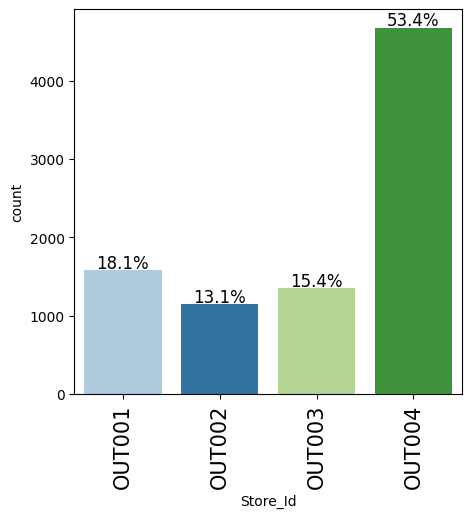

In [24]:
labeled_barplot(data, "Store_Id", perc=True)

**OBSERVATIONS**:



---


- Based on the barplot for Store_Id, there are only 4 distinct Store Ids. Although we have more than 50% of data for Store_Id: OUT004

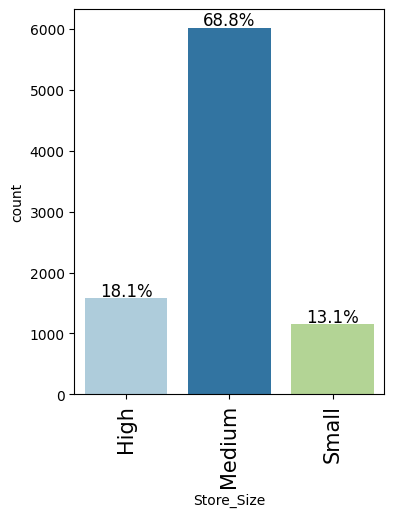

In [25]:
labeled_barplot(data, "Store_Size", perc=True)

**OBSERVATIONS**:

---
- Seems like Store_Size is also a categorical columns with 3 categories: High, Medium, Small. Medium makes up 68.8% of dataset for revenue.

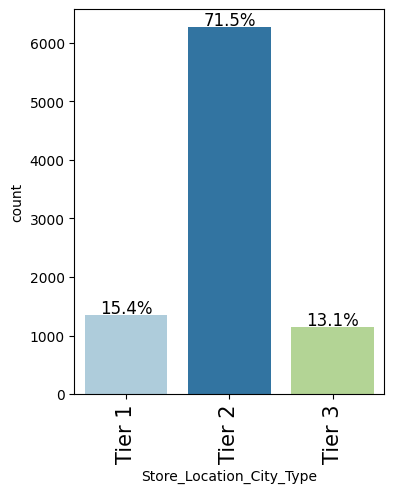

In [26]:
labeled_barplot(data, "Store_Location_City_Type", perc=True)

**OBSERVATIONS**:

---
- This bar plot also indicates that Store_Location_City_Type has 3 distinct values: Tier 1, 2 and 3. Here Tier 2 might be the highest revenue generating as it is 71.5% of the dataset.

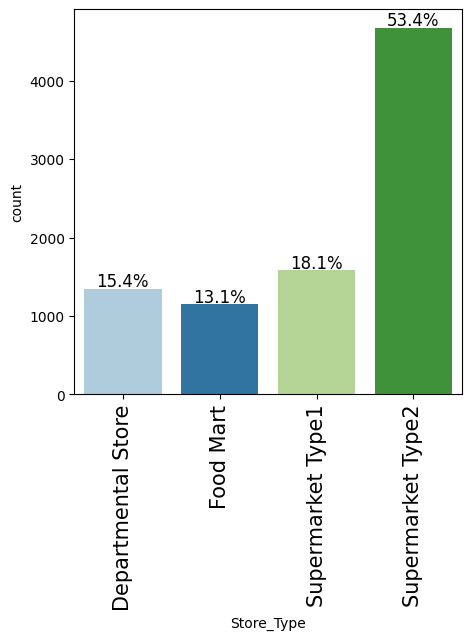

In [27]:
labeled_barplot(data, "Store_Type", perc=True)

**OBSERVATIONS**:

---
- The barplot for Store_Type indicates that there are 4 types of stores with Supermarket Type 2 contributing to more than 50% of the dataset.

**OBSERVATIONS**:


---

- Conclusion: Columns to be converted to categorical : Product_Sugar_Content, Store_Id, Store_Establishment_Year, Store_Size, Store_Location_City_Type, Store_Type

## Bivariate Analysis

Correlation matrix

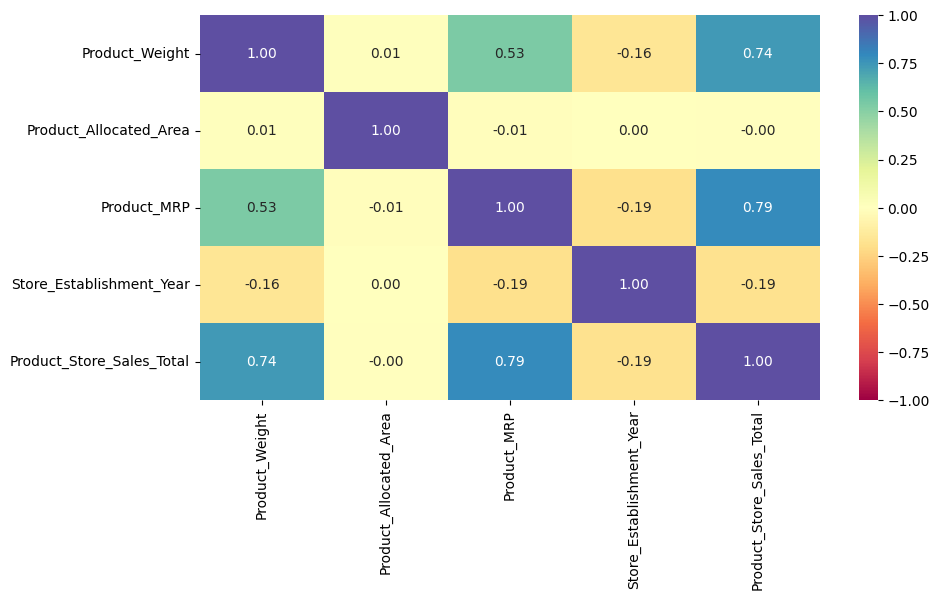

In [28]:
cols_list = data.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(10, 5))
sns.heatmap(
    data[cols_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()

**OBSERVATIONS**:


---

- Based on the correlation matrix, we observe that **Product_Weight** and **Product_MRP** have a **strong positive** correlation w.r.t. the sales (Product_Store_Sales_Total)
- There is no other strong positive or negative correlation to Product_Store_Sales_total
- Seems like **Product_Allocated_Area** has **no effect** on Product_Store_Sales_Total (target) So we can probably drop this column




### Distribution of target variable w.r.t. numeric columns

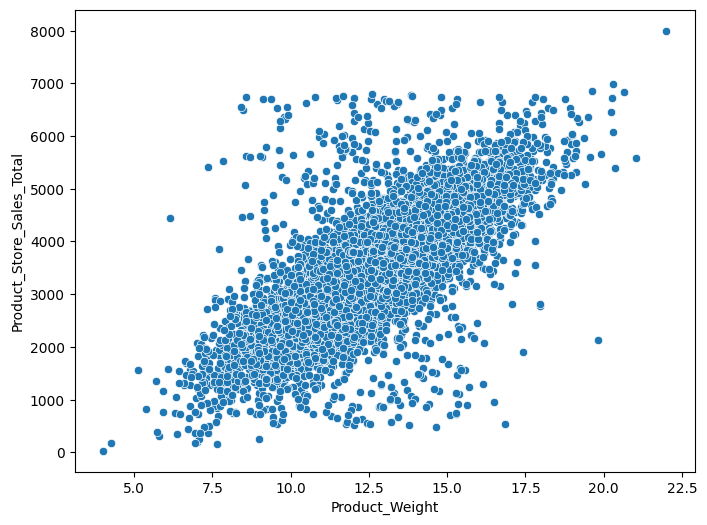

In [29]:
plt.figure(figsize=[8, 6])
sns.scatterplot(x=data['Product_Weight'], y=data['Product_Store_Sales_Total'])
plt.show()

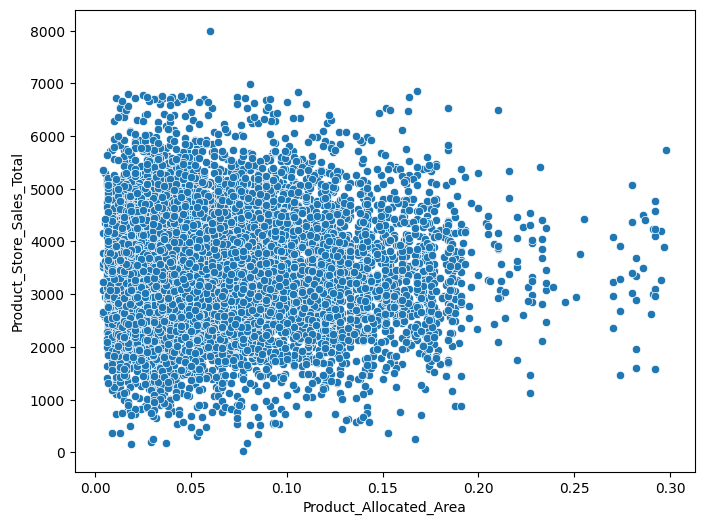

In [30]:
plt.figure(figsize=[8, 6])
sns.scatterplot(x=data['Product_Allocated_Area'], y=data['Product_Store_Sales_Total'])
plt.show()

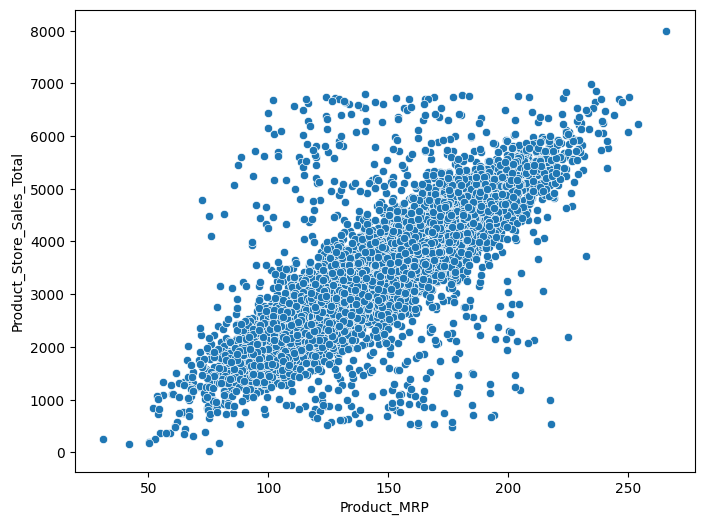

In [31]:
plt.figure(figsize=[8, 6])
sns.scatterplot(x=data['Product_MRP'], y=data['Product_Store_Sales_Total'])
plt.show()

**OBSERVATIONS**:


---

The scatter plot confirms the same observation as the correlation matrix.
- Higher Product MRP, Higher Sales
- Higher Product Weight, Higher Sales
- Product Allocated Area does not give any insight into Product Sales.

### Product type delivering highest sales revenue

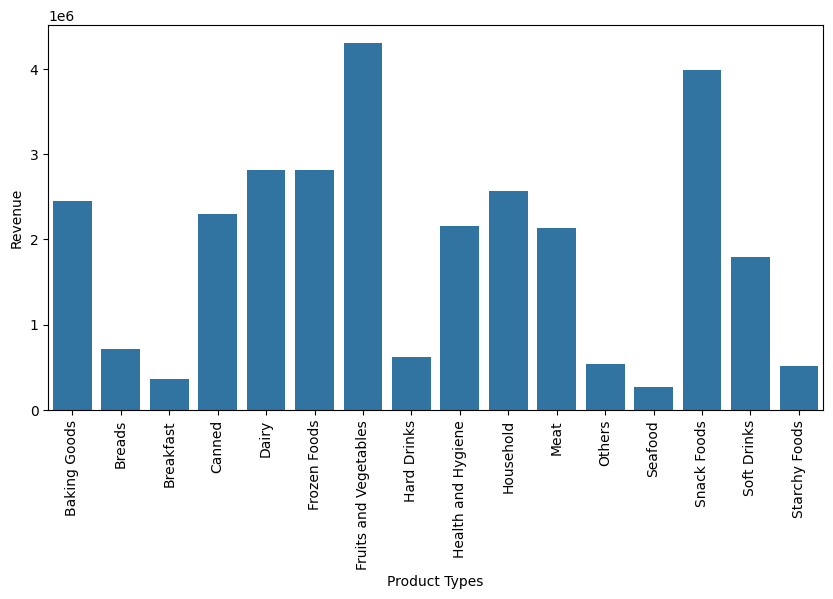

In [32]:
df_revenue1 = data.groupby(["Product_Type"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
plt.figure(figsize=[10, 5])
plt.xticks(rotation=90)
a = sns.barplot(x=df_revenue1.Product_Type, y=df_revenue1.Product_Store_Sales_Total)
a.set_xlabel("Product Types")
a.set_ylabel("Revenue")
plt.show()

**OBSERVATIONS**:


---

- Fruits and Vegetables and Snack Foods contribute the highest revenue.
- Seafood and Breakfast contribute the lowest revenue.

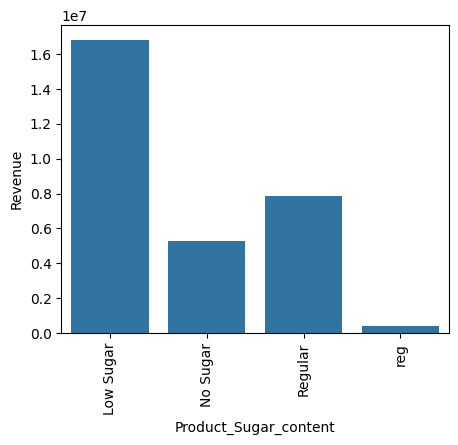

In [33]:
df_revenue2 = data.groupby(["Product_Sugar_Content"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
plt.figure(figsize=[5, 4])
plt.xticks(rotation=90)
b = sns.barplot(
    x=df_revenue2.Product_Sugar_Content, y=df_revenue2.Product_Store_Sales_Total
)
b.set_xlabel("Product_Sugar_content")
b.set_ylabel("Revenue")
plt.show()

**OBSERVATIONS**:

---
- Low Sugar Products contribute to the highest revenue, followed by Regular ( considering: Regular + reg) and later by No Sugar.

### Stores and locations impacting highest sales revenue

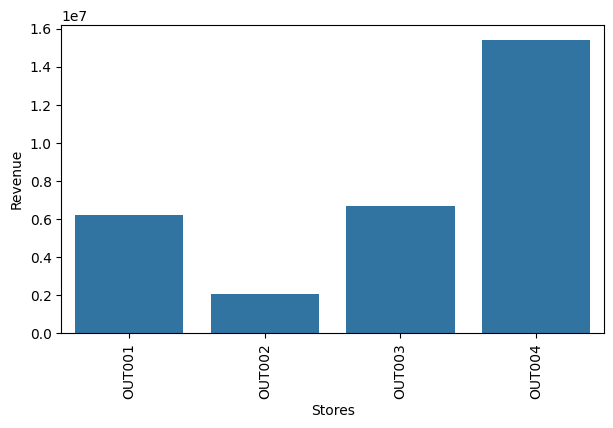

In [34]:
df_store_revenue = data.groupby(["Store_Id"], as_index=False)["Product_Store_Sales_Total"].sum()
plt.figure(figsize=[7,4])
plt.xticks(rotation=90)
r = sns.barplot(x=df_store_revenue.Store_Id, y=df_store_revenue.Product_Store_Sales_Total)
r.set_xlabel("Stores")
r.set_ylabel("Revenue")
plt.show()

**OBSERVATIONS**:

---
- Store: OUT004 contributes to the highest revenue, significantly higher than other 3

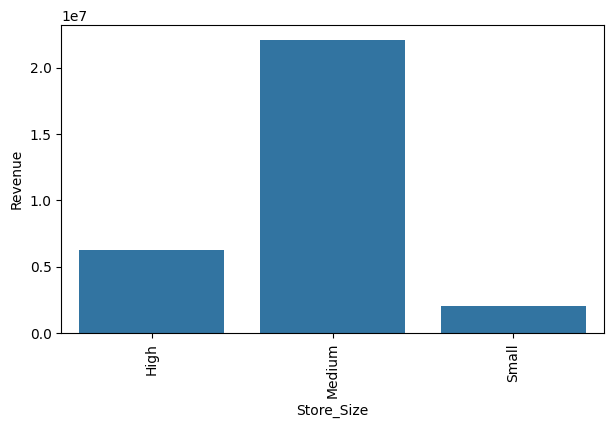

In [35]:
df_revenue3 = data.groupby(["Store_Size"], as_index=False)["Product_Store_Sales_Total"].sum()
plt.figure(figsize=[7, 4])
plt.xticks(rotation=90)
c = sns.barplot(x=df_revenue3.Store_Size, y=df_revenue3.Product_Store_Sales_Total)
c.set_xlabel("Store_Size")
c.set_ylabel("Revenue")
plt.show()

**OBSERVATIONS**:

---
- Medium Store_Size contribute to the highest revenue, followed by High and then Small.

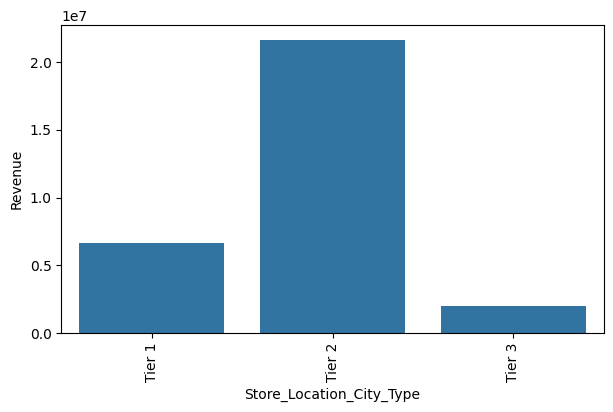

In [36]:
df_revenue4 = data.groupby(["Store_Location_City_Type"], as_index=False)["Product_Store_Sales_Total"].sum()
plt.figure(figsize=[7, 4])
plt.xticks(rotation=90)
d = sns.barplot(x=df_revenue4.Store_Location_City_Type, y=df_revenue4.Product_Store_Sales_Total)
d.set_xlabel("Store_Location_City_Type")
d.set_ylabel("Revenue")
plt.show()

**OBSERVATIONS**:

---
- Low Sugar Products contribute to the highest revenue, followed by Regular ( considering: Regular + reg) and later by No Sugar.

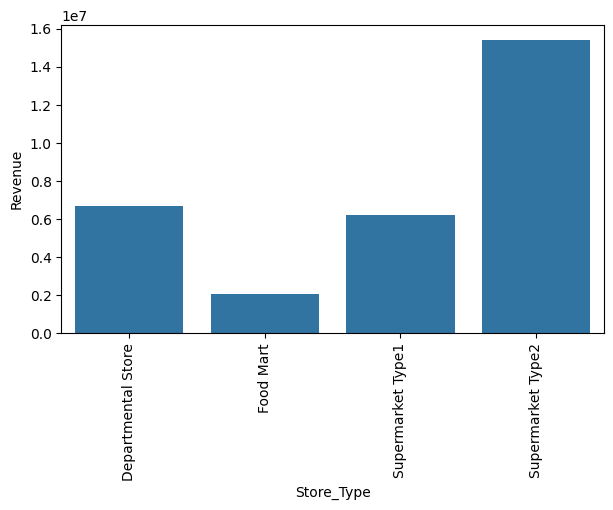

In [37]:
df_revenue5 = data.groupby(["Store_Type"], as_index=False)["Product_Store_Sales_Total"].sum()
plt.figure(figsize=[7, 4])
plt.xticks(rotation=90)
e = sns.barplot(x=df_revenue5.Store_Type, y=df_revenue5.Product_Store_Sales_Total)
e.set_xlabel("Store_Type")
e.set_ylabel("Revenue")
plt.show()

**OBSERVATIONS**:

---
- The Supermarket Type2 Store_Type contributes the highest revenue whereas FoodMart contributes the lowest

### Distribution of our target variable: Product_Store_Sales_Total with the other categorical columns

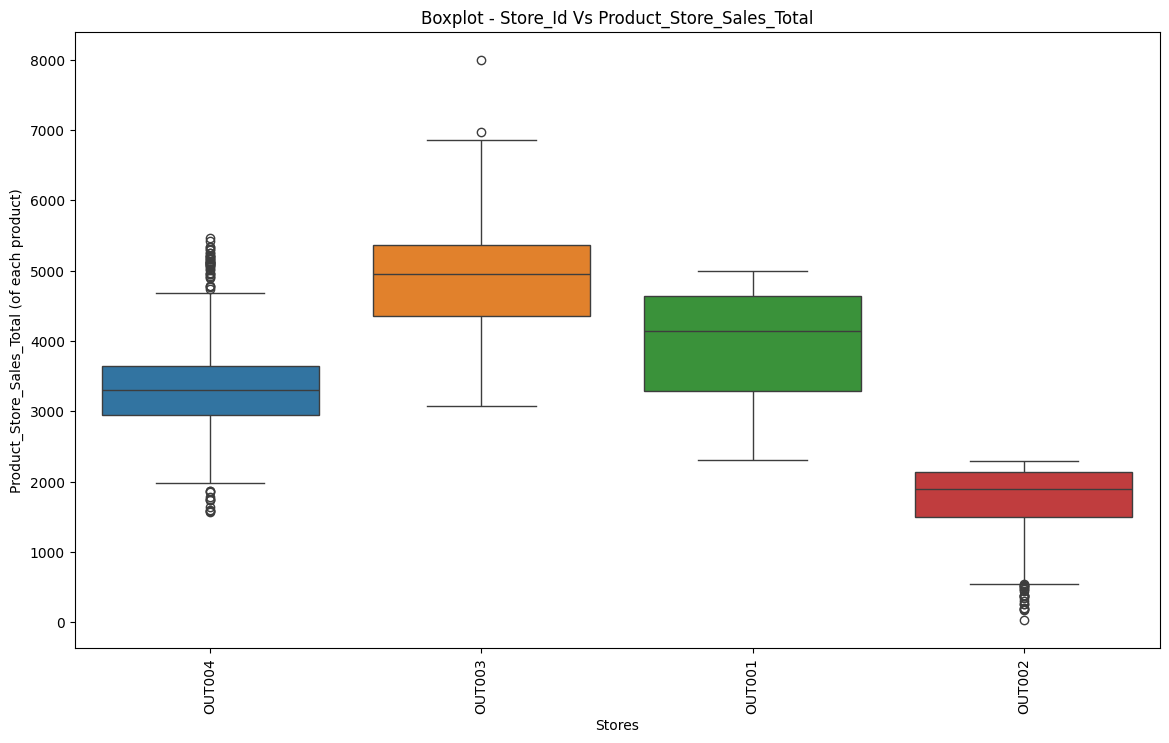

In [38]:
plt.figure(figsize=[14, 8])
sns.boxplot(data=data, x="Store_Id", y="Product_Store_Sales_Total", hue = "Store_Id")
plt.xticks(rotation=90)
plt.title("Boxplot - Store_Id Vs Product_Store_Sales_Total")
plt.xlabel("Stores")
plt.ylabel("Product_Store_Sales_Total (of each product)")
plt.show()

**OBSERVATIONS**:

---
- The plotting of actual revenue distribution vs the Store Ids gives us an interesting insight that although the revenue from the Store: OUT004 is the highest, the average cost of the sales is not the highest for the same. The median value is ~3400 which is less than that of OUT001 and OUT003.
- This means that OUT004 has more number of sales than the other stores which makes it the store with the highest revenue.

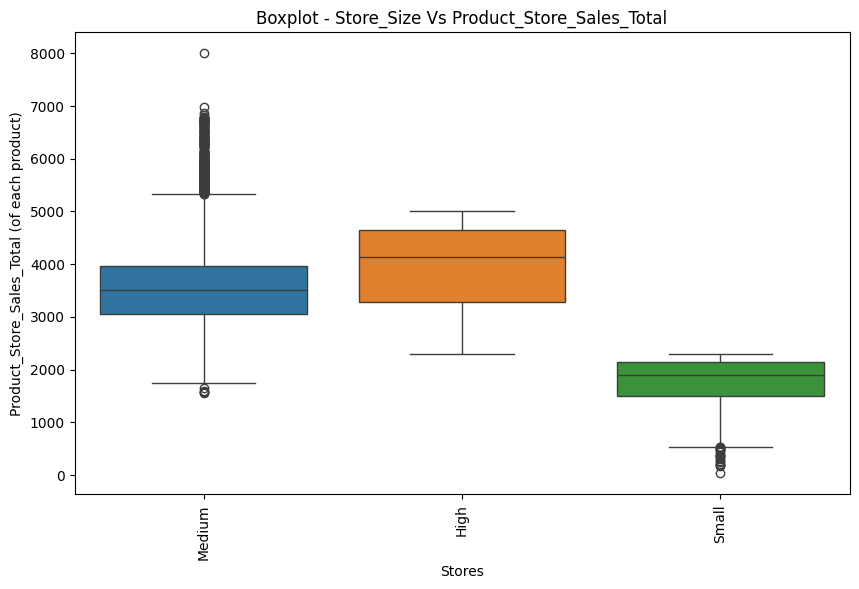

In [39]:
plt.figure(figsize=[10, 6])
sns.boxplot(data = data, x = "Store_Size", y = "Product_Store_Sales_Total", hue = "Store_Size")
plt.xticks(rotation=90)
plt.title("Boxplot - Store_Size Vs Product_Store_Sales_Total")
plt.xlabel("Stores")
plt.ylabel("Product_Store_Sales_Total (of each product)")
plt.show()

**OBSERVATIONS**:

---

- Although Store Size: High has highest median value of the sales, Store_Size Medium has the maximum number of sales which in conjunction of viewing with the earlier graph shows that Store_Size Medium produces the highest revenue.

### Relationship between the other columns

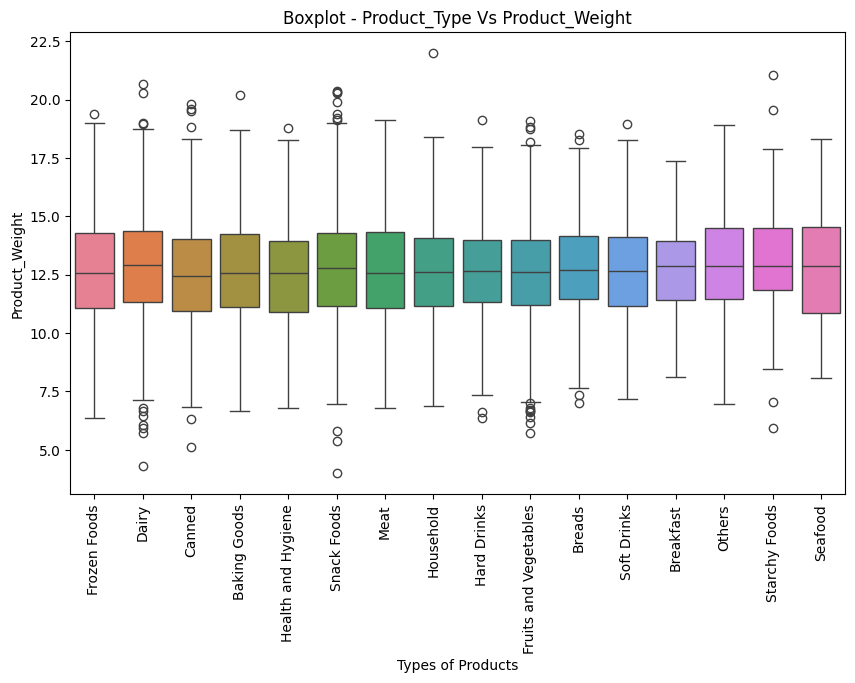

In [40]:
plt.figure(figsize=[10, 6])
sns.boxplot(data = data, x = "Product_Type", y = "Product_Weight", hue = "Product_Type")
plt.xticks(rotation=90)
plt.title("Boxplot - Product_Type Vs Product_Weight")
plt.xlabel("Types of Products")
plt.ylabel("Product_Weight")
plt.show()

**OBSERVATIONS**:


---

- The Product Weight median of most of the categories of food is the same around 12.5. So Product Weight should not matter in the Sales.

### Checking for relationship between the weight of the product and its sugar content

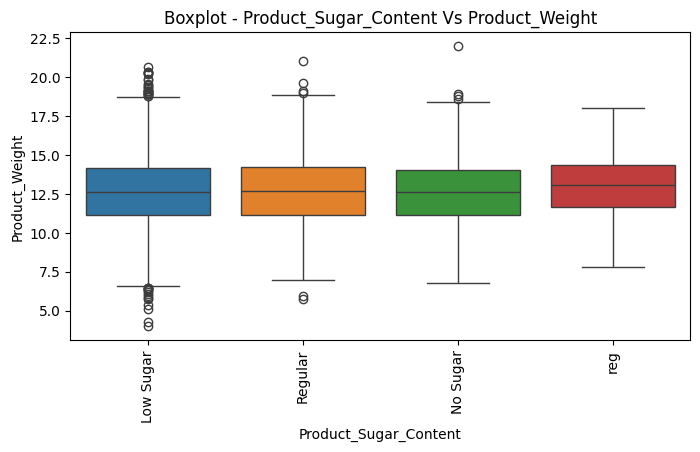

In [41]:
plt.figure(figsize=[8, 4])
sns.boxplot(data = data, x = "Product_Sugar_Content", y = "Product_Weight", hue = "Product_Sugar_Content")
plt.xticks(rotation=90)
plt.title("Boxplot - Product_Sugar_Content Vs Product_Weight")
plt.xlabel("Product_Sugar_Content")
plt.ylabel("Product_Weight")
plt.show()

**OBSERVATIONS**:


---

- The Product Weight median of all caltegories of Product_Sugar_Content is the same around 12.5. So Product Weight should not matter in the Sales.
- So by comparing Product Weight against the 2 features contributing to variance in Product Sales we conclude that Product Weight should also not matter for Sales.

### Analyze the sugar content of different product types

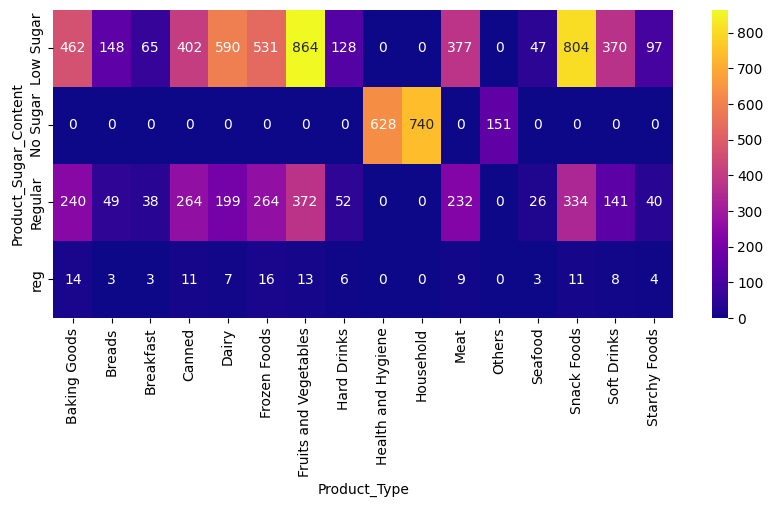

In [42]:
plt.figure(figsize=(10, 4))
sns.heatmap(
    pd.crosstab(data["Product_Sugar_Content"], data["Product_Type"]),
    annot=True,
    fmt="g",
    cmap="plasma",
)
plt.ylabel("Product_Sugar_Content")
plt.xlabel("Product_Type")
plt.show()

**OBSERVATIONS**:


---
- Baking goods, Canned, Dairy and Frozen Foods , as expected have high sugar as compared to health and hygiene and Household items.
- SuperKart seems to be having a lot of Low Sugar options for each category as applicable.


### How many items of each product type has been sold in each of the stores

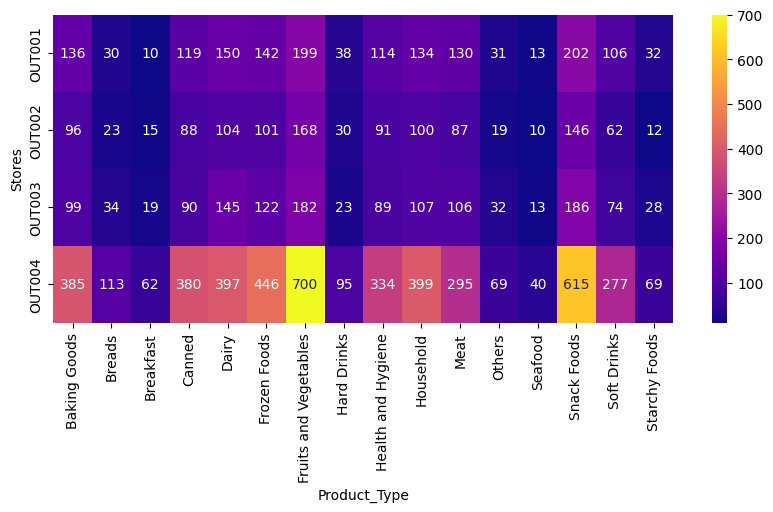

In [43]:
plt.figure(figsize=(10, 4))
sns.heatmap(
    pd.crosstab(data["Store_Id"], data["Product_Type"]),
    annot=True,
    fmt="g",
    cmap="plasma",
)
plt.ylabel("Stores")
plt.xlabel("Product_Type")
plt.show()

**OBSERVATIONS**:

---
- Fruits and Vegetables at OUT004 have around 700 items sold at OUT004. Snack Foods stand second at 615 items. OUT004 has the max products sold.


### Different product types have different prices. Let's analyze the trend.

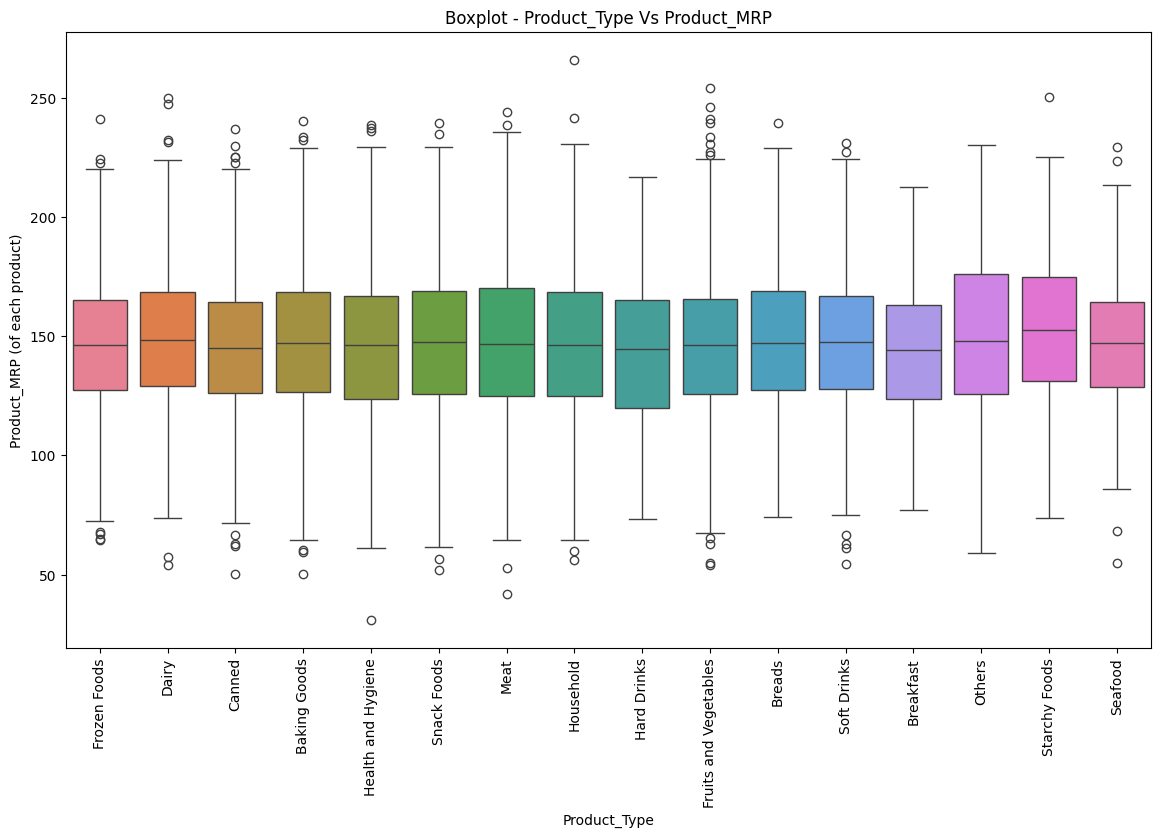

In [44]:
plt.figure(figsize=[14, 8])
sns.boxplot(data = data, x = "Product_Type", y = "Product_MRP", hue = "Product_Type")
plt.xticks(rotation=90)
plt.title("Boxplot - Product_Type Vs Product_MRP")
plt.xlabel("Product_Type")
plt.ylabel("Product_MRP (of each product)")
plt.show()

**OBSERVATIONS**:


---
- The median prices of each of the product types are more or less the same.


### Let's find out how the Product_MRP varies with the different stores

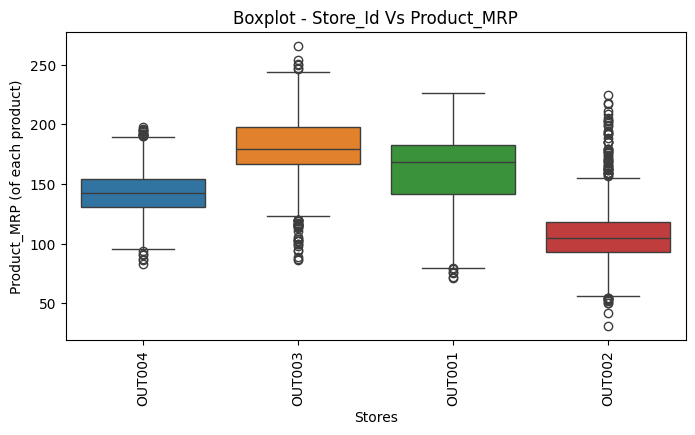

In [45]:
plt.figure(figsize=[8, 4])
sns.boxplot(data = data, x = "Store_Id", y = "Product_MRP", hue = "Store_Id")
plt.xticks(rotation=90)
plt.title("Boxplot - Store_Id Vs Product_MRP")
plt.xlabel("Stores")
plt.ylabel("Product_MRP (of each product)")
plt.show()

**OBSERVATIONS**:

---
- OUT003 Store has highest avg. median price. OUT001 is next, OUT004 is 3rd with avg price around 145, OUT002 the lowest.


### Let's delve deeper and do a detailed analysis of each of the stores.

#### OUT001

In [46]:
data.loc[data["Store_Id"] == "OUT001"].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,1586,1586,NC7187,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,1586.0,NaN,NaN,NaN,13.458865,2.064975,6.16,12.0525,13.96,14.95,17.97
Product_Sugar_Content,1586,4,Low Sugar,845,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,1586.0,NaN,NaN,NaN,0.068768,0.047131,0.004,0.033,0.0565,0.094,0.295
Product_Type,1586,16,Snack Foods,202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,1586.0,NaN,NaN,NaN,160.514054,30.359059,71.35,141.72,168.32,182.9375,226.59
Store_Id,1586,1,OUT001,1586,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,1586.0,NaN,NaN,NaN,1987.0,0.0,1987.0,1987.0,1987.0,1987.0,1987.0
Store_Size,1586,1,High,1586,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,1586,1,Tier 2,1586,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observations**

Based on the Top and mean columns,
- OUT001 is a store of **Supermarket Type 1**, located in a **Tier 2** city with **store size as high**. It was established in **1987**.
- OUT001 has sold products whose **MRP range from 71 to 227**.
- **Snack Foods** have been sold the highest number of times in OUT001.
- The **revenue** generated from each product at OUT001 **ranges from 2300 to 5000**.

In [47]:
data.loc[data["Store_Id"] == "OUT001", "Product_Store_Sales_Total"].sum()

np.float64(6223113.18)

**Observations**

- OUT001 has generated total revenue of **6,223,113** from the sales of goods.

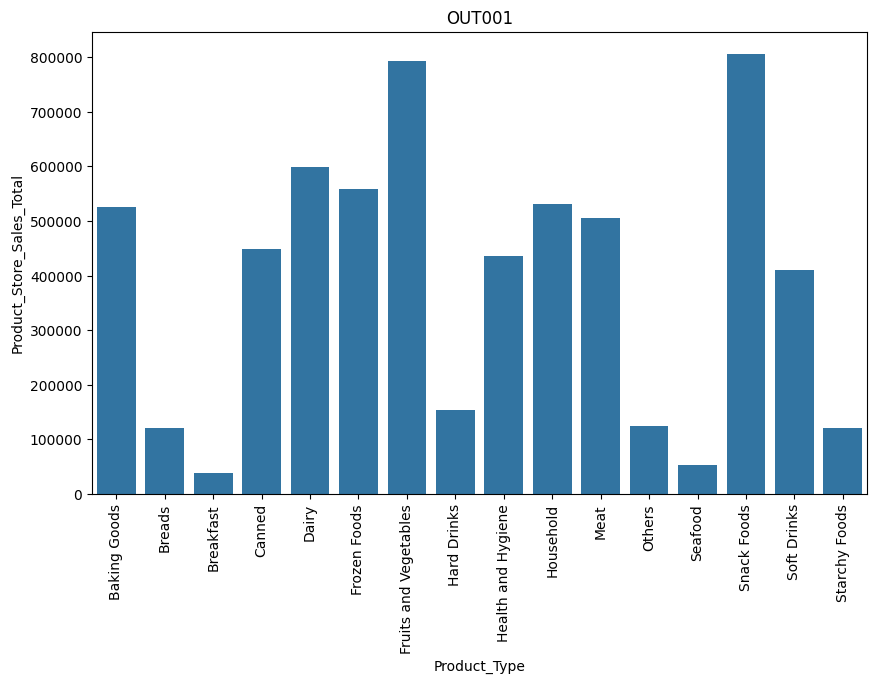

In [48]:
df_OUT001 = (
    data.loc[data["Store_Id"] == "OUT001"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"]
    .sum()
)
plt.figure(figsize=[10, 6])
plt.xticks(rotation=90)
plt.xlabel("Product_Type")
plt.ylabel("Product_Store_Sales_Total")
plt.title("OUT001")
sns.barplot(x=df_OUT001.Product_Type, y=df_OUT001.Product_Store_Sales_Total)
plt.show()

**Observations**

- OUT001 has generated the highest revenue from the sale of fruits and vegetables and snack foods. Both the categories have contributed around 800000 each.

#### OUT002

In [49]:
data.loc[data["Store_Id"] == "OUT002"].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,1152,1152,NC2769,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,1152.0,NaN,NaN,NaN,9.911241,1.799846,4.0,8.7675,9.795,10.89,19.82
Product_Sugar_Content,1152,4,Low Sugar,658,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,1152.0,NaN,NaN,NaN,0.067747,0.047567,0.006,0.031,0.0545,0.09525,0.292
Product_Type,1152,16,Fruits and Vegetables,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,1152.0,NaN,NaN,NaN,107.080634,24.912333,31.0,92.8275,104.675,117.8175,224.93
Store_Id,1152,1,OUT002,1152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,1152.0,NaN,NaN,NaN,1998.0,0.0,1998.0,1998.0,1998.0,1998.0,1998.0
Store_Size,1152,1,Small,1152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,1152,1,Tier 3,1152,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observations**

- OUT002 is a food mart which is located in a **Tier 3** city and has **store size as small**. It was established in **1998**.
- OUT002 has sold products whose MRP range from **31 to 225**.
- **Fruits and vegetables** have been sold the highest number of times in OUT002.
- The **revenue** generated from each product at OUT002 ranges from **33 to 2300**.

In [50]:
data.loc[data["Store_Id"] == "OUT002", "Product_Store_Sales_Total"].sum()

np.float64(2030909.72)

**Observations**:

- OUT002 has generated total revenue of **2,030,910** from the sales of goods.

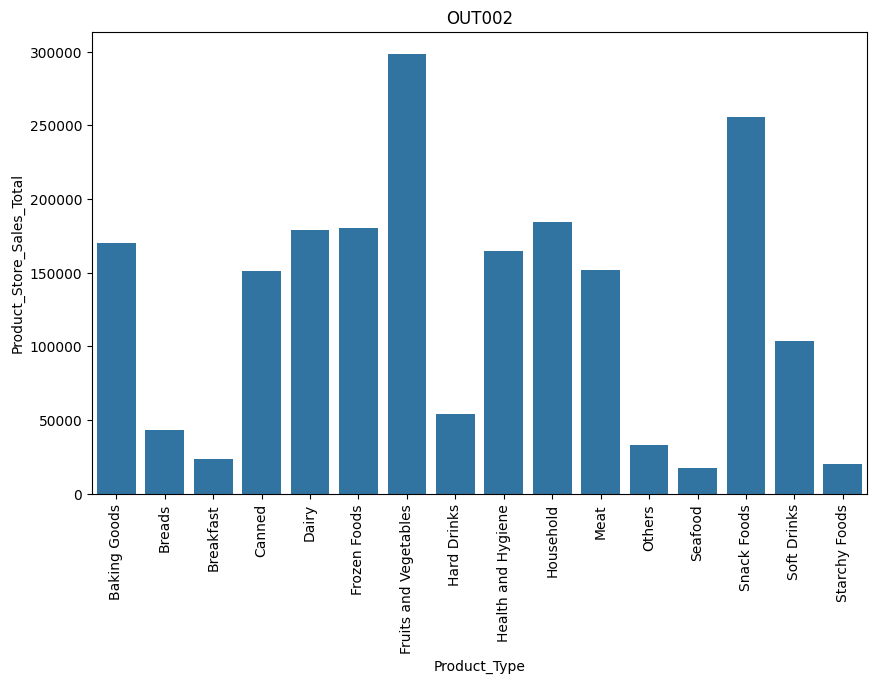

In [51]:
df_OUT002 = (
    data.loc[data["Store_Id"] == "OUT002"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"]
    .sum()
)
plt.figure(figsize=[10, 6])
plt.xticks(rotation=90)
plt.xlabel("Product_Type")
plt.ylabel("Product_Store_Sales_Total")
plt.title("OUT002")
sns.barplot(x=df_OUT002.Product_Type, y=df_OUT002.Product_Store_Sales_Total)
plt.show()

**Observations**:

- OUT002 has generated the highest revenue from the sale of fruits and vegetables (~ 300000) followed by snack foods (~ 250000).

#### OUT003

In [52]:
data.loc[data["Store_Id"] == "OUT003"].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,1349,1349,NC522,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,1349.0,NaN,NaN,NaN,15.103692,1.893531,7.35,14.02,15.18,16.35,22.0
Product_Sugar_Content,1349,4,Low Sugar,750,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,1349.0,NaN,NaN,NaN,0.068637,0.048708,0.004,0.031,0.057,0.094,0.298
Product_Type,1349,16,Snack Foods,186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,1349.0,NaN,NaN,NaN,181.358725,24.796429,85.88,166.92,179.67,198.07,266.0
Store_Id,1349,1,OUT003,1349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,1349.0,NaN,NaN,NaN,1999.0,0.0,1999.0,1999.0,1999.0,1999.0,1999.0
Store_Size,1349,1,Medium,1349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,1349,1,Tier 1,1349,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observations**
- OUT003 is a Departmental store which is located in a Tier 1 city and has store size as medium. It was established in 1999.
- OUT003 has sold products whose MRP range from 86 to 266.
- Snack Foods have been sold the highest number of times in OUT003.
- The revenue generated from each product at OUT003 ranges from 3070 to 8000.

In [53]:
data.loc[data["Store_Id"] == "OUT003", "Product_Store_Sales_Total"].sum()

np.float64(6673457.57)

**Observations**

- OUT003 has generated total revenue of 6673458 from the sales of goods.

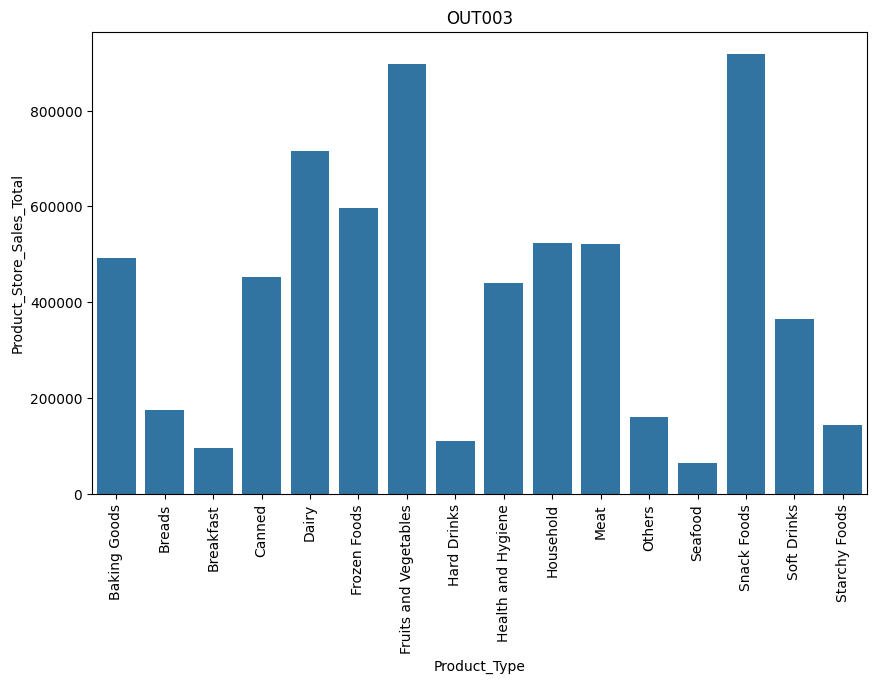

In [54]:
df_OUT003 = (
    data.loc[data["Store_Id"] == "OUT003"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"]
    .sum()
)
plt.figure(figsize=[10, 6])
plt.xticks(rotation=90)
plt.xlabel("Product_Type")
plt.ylabel("Product_Store_Sales_Total")
plt.title("OUT003")
sns.barplot(x=df_OUT003.Product_Type, y=df_OUT003.Product_Store_Sales_Total)
plt.show()

**Observations**:

- OUT003 has generated the highest revenue from the sale of snack foods followed by fruits and vegetables, both the categories contributing around 800000 each.

#### OUT004

In [55]:
data.loc[data["Store_Id"] == "OUT004"].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,4676,4676,NC584,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,4676.0,NaN,NaN,NaN,12.349613,1.428199,7.34,11.37,12.37,13.3025,17.79
Product_Sugar_Content,4676,4,Low Sugar,2632,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,4676.0,NaN,NaN,NaN,0.069092,0.048584,0.004,0.031,0.056,0.097,0.297
Product_Type,4676,16,Fruits and Vegetables,700,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,4676.0,NaN,NaN,NaN,142.399709,17.513973,83.04,130.54,142.82,154.1925,197.66
Store_Id,4676,1,OUT004,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,4676.0,NaN,NaN,NaN,2009.0,0.0,2009.0,2009.0,2009.0,2009.0,2009.0
Store_Size,4676,1,Medium,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,4676,1,Tier 2,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observations**

- OUT004 is a store of **Supermarket Type2** which is located in a **Tier 2** city and has **store size as medium**. It was established in **2009**.
- OUT004 has sold products whose **MRP range from 83 to 198**.
- **Fruits and vegetables** have been sold the highest number of times in OUT004.
- The **revenue** generated from each product at OUT004 **ranges from 1561 to 5463**.

In [56]:
data.loc[data["Store_Id"] == "OUT004", "Product_Store_Sales_Total"].sum()

np.float64(15427583.43)

**Observations**

- OUT004 has generated total revenue of **15,427,583** from the sales of goods which is highest among all the 4 stores.

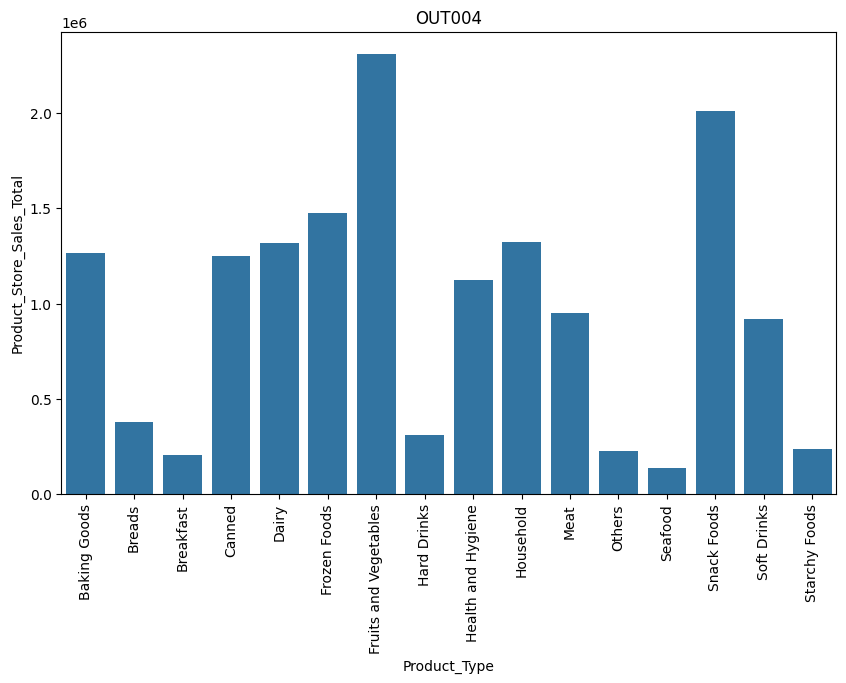

In [57]:
df_OUT004 = (
    data.loc[data["Store_Id"] == "OUT004"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"]
    .sum()
)
plt.figure(figsize=[10, 6])
plt.xticks(rotation=90)
plt.xlabel("Product_Type")
plt.ylabel("Product_Store_Sales_Total")
plt.title("OUT004")
sns.barplot(x=df_OUT004.Product_Type, y=df_OUT004.Product_Store_Sales_Total)
plt.show()

**Observations**:

- OUT004 has generated the highest revenue from the sale of fruits and vegetables (~ 2500000) followed by snack foods (~ 2000000).

#### Let's find out the revenue generated by the stores from each of the product types.

In [58]:
df1 = data.groupby(["Product_Type", "Store_Id"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
df1

,Product_Type,Store_Id,Product_Store_Sales_Total
0,Baking Goods,OUT001,525131.04
1,Baking Goods,OUT002,169860.50
2,Baking Goods,OUT003,491908.20
3,Baking Goods,OUT004,1266086.26
4,Breads,OUT001,121274.09
5,Breads,OUT002,43419.47
6,Breads,OUT003,175391.93
7,Breads,OUT004,374856.75
8,Breakfast,OUT001,38161.10
9,Breakfast,OUT002,23396.10


**Observations**:


---
- In all the product types, revenue generated by **OUT004** is **highest** which is expected since **~53%** of the total products were brought from this store.
- In all the product categories, revenue generated by **OUT002** is **lowest** which is expected since it is **small** store in a **Tier 3** city.

#### Let's find out the revenue generated by the stores from products having different levels of sugar content

In [59]:
df2 = data.groupby(["Product_Sugar_Content", "Store_Id"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
df2

,Product_Sugar_Content,Store_Id,Product_Store_Sales_Total
0,Low Sugar,OUT001,3300834.93
1,Low Sugar,OUT002,1156758.85
2,Low Sugar,OUT003,3706903.24
3,Low Sugar,OUT004,8658908.78
4,No Sugar,OUT001,1090353.78
5,No Sugar,OUT002,382162.19
6,No Sugar,OUT003,1123084.57
7,No Sugar,OUT004,2674343.14
8,Regular,OUT001,1749444.51
9,Regular,OUT002,472112.50


**Observations**:

- The trend is the same as that which was present in the revenue analysis of stores for product types.

# **Data Preprocessing**

## **Cleaning up: Product_Sugar_Content column**

- The Product_Sugar_Content column has 4 types - Low Sugar, No Sugar, Regular and reg. Regular and reg will be referring to the same type. So let's combine reg into Regular.

In [60]:
# Replacing reg with Regular
data.Product_Sugar_Content.replace(to_replace=["reg"], value=["Regular"], inplace=True)

In [61]:
data.Product_Sugar_Content.value_counts()

,count
Product_Sugar_Content,
Low Sugar,4885
Regular,2359
No Sugar,1519


## **Exploring Patterns in Product_IDs**

- We can see that the Product_Id column has two characters followed by a number.

- Let's delve deeper and see whether they are having any relationship with the other columns or not

In [62]:
## extracting the first two characters from the Product_Id column and storing it in another column
data["Product_Id_char"] = data["Product_Id"].str[:2]
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC


In [63]:
data["Product_Id_char"].unique()

array(['FD', 'NC', 'DR'], dtype=object)

In [64]:
data.loc[data.Product_Id_char == "FD", "Product_Type"].unique()

array(['Frozen Foods', 'Dairy', 'Canned', 'Baking Goods', 'Snack Foods',
       'Meat', 'Fruits and Vegetables', 'Breads', 'Breakfast',
       'Starchy Foods', 'Seafood'], dtype=object)

In [65]:
data.loc[data.Product_Id_char == "DR", "Product_Type"].unique()

array(['Hard Drinks', 'Soft Drinks'], dtype=object)

In [66]:
data.loc[data.Product_Id_char == "NC", "Product_Type"].unique()

array(['Health and Hygiene', 'Household', 'Others'], dtype=object)

**OBSERVATIONS**:


---
- So it seems like Product Ids have 3 unique starting 2 char codes: FD (Foods), DR (Drinks), NC ( Non consumable, possibly)
- So we could convert this into categorical column if needed.


## **Store's Age**

- A store which has been in the business for a long duration is more trustworthy than the newly established ones.

- On the other hand, older stores may sometimes lack infrastructure if proper attention is not given. So let us calculate the current age of the store and incorporate that in our model.

In [67]:
data["Store_Age_Years"] = 2026 - data.Store_Establishment_Year
data["Store_Age_Years"].unique()

array([17, 27, 39, 28])

## **Outlier Check**

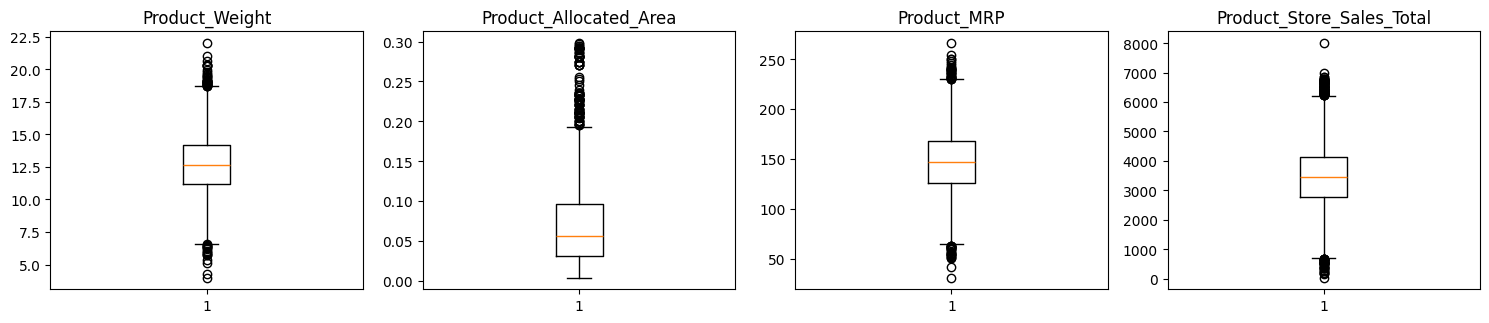

In [68]:
# outlier detection using boxplot
numeric_columns = data.select_dtypes(include=np.number).columns.tolist()
numeric_columns.remove("Store_Establishment_Year")
numeric_columns.remove("Store_Age_Years")


plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(data[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

**OBSERVATIONS**:

---
- For the numerical columns, besides Store Age and years, we plotted box plot to analyse outliers.
- It seems like all 4 features (3 features and our taget var: Product_Store_Sales_Total) have outliers. Let us tr


## **Data Preparation for Modeling**

- We aim to forecast the Product_Store_Sales_Total.

- Before building the model, we'll drop unnecessary columns and encode the categorical features.

- We'll then split the data into training and testing sets to evaluate the model's performance on unseen data.

In [69]:
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char,Store_Age_Years
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD,17
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD,27
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD,39
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD,39
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC,28


### Drop unnecessary columns and create a list of categorical columns for one hot encoding

In [70]:
categorical_features = data.select_dtypes(include=['object', 'category']).columns.tolist()
categorical_features

['Product_Id',
 'Product_Sugar_Content',
 'Product_Type',
 'Store_Id',
 'Store_Size',
 'Store_Location_City_Type',
 'Store_Type',
 'Product_Id_char']

In [71]:
categorical_features.remove("Product_Id")
data.drop(columns="Product_Id", inplace=True)

In [72]:
data.drop(columns=["Store_Establishment_Year"], inplace=True)

In [73]:
data.head()

,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char,Store_Age_Years
0,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,Medium,Tier 2,Supermarket Type2,2842.40,FD,17
1,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,Medium,Tier 1,Departmental Store,4830.02,FD,27
2,14.28,Regular,0.031,Canned,162.08,OUT001,High,Tier 2,Supermarket Type1,4130.16,FD,39
3,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,High,Tier 2,Supermarket Type1,4132.18,FD,39
4,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,Small,Tier 3,Food Mart,2279.36,NC,28


In [74]:
data.columns

Index(['Product_Weight', 'Product_Sugar_Content', 'Product_Allocated_Area',
       'Product_Type', 'Product_MRP', 'Store_Id', 'Store_Size',
       'Store_Location_City_Type', 'Store_Type', 'Product_Store_Sales_Total',
       'Product_Id_char', 'Store_Age_Years'],
      dtype='object')

**OBSERVATIONS**:


---

SUMMARY:

- Product_Id------------------| This is not useful, instead using: Product_Id_char | Dropped
- Product_Weight-------------| is Numeric  | Retained
- Product_Sugar_Content-----| One Hot encoding  | Retained
- Product_Allocated_Area-----| is Numeric  | Retained
- Product_Type---------------| One Hot encoding  | Retained
- Product_MRP---------------|  is Numeric  | Retained
- Store_Id--------------------| One Hot encoding  | Retained
- Store_Establishment_Year---| Converted to Store_Age_Years | Dropped
- Store_Size------------------| One Hot encoding  | Retained
- Store_Location_City_Type---| One Hot encoding  | Retained
- Store_Type-----------------| One Hot encoding  | Retained
- Product_Store_Sales_Total--| Target column | Dropped
- Product_Id_char------------| New column based on ProductId : One hot encoding| Retained
- Store_Age_Years-----------| New column based on Store Establishment Year | Retained


---

- **One Hot encoding** | Retained columns are categorical columns which will be processed and converted to numeric using the preprocessor for each model
- The other retained columns will be numeric.
- **Data leakage handling**: Since we are plain converting to one hot encoding and not replacing any unknown data with mean or anything, hence we are ensuring that there is no dataleakage. Else we would do this separately for training and testing set.




### Training and testing set prep

In [78]:
# Separating features and the target column
X = data.drop("Product_Store_Sales_Total", axis=1)
y = data["Product_Store_Sales_Total"]

In [79]:
# Splitting the data into train and test sets in 80:20 ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

In [80]:
X_train.shape, X_test.shape

((7010, 11), (1753, 11))

**OBSERVATIONS**:


---
- Here we are creating a training and testing data set for our model to be trained on and tested on. BY using random_state=42 we will ensure that the same data gets picked everytime we select the data for training and testing, ensuring no data leakage

### Data Pre-processing Pipeline

In [81]:
# Create a preprocessing pipeline for the categorical features
preprocessor = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_features),
    (StandardScaler(), X_train.select_dtypes(include=np.number).columns.tolist()),
    remainder='drop' # Explicitly drop any other columns not specified
)

**OBSERVATIONS**:


---

- We are performing One Hot encoding for categorical columns and ignoring the unknown values. This is a safety check ,since we already established earlier that we do not have any missing values and no duplicates too.
- For the numeric values, we are using Standard Scaler to handle outliers from affecting the dataset.
- Since the outliers are also important and significant in number based on earlier analysis, hence we did not drop them.
- as a safety check, we are dropping the unhandled columns.

# **Model Building**

## Define functions for Model Evaluation

In [82]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

The ML models to be built can be any two out of the following:
1. Decision Tree
2. Bagging
3. **Random Forest**
4. AdaBoost
5. Gradient Boosting
6. **XGBoost**

**OBSERVATIONS**:


---

- Since we need a prediction regresssion model, Let's choose Random Forest ( parallel processing, simpler model good for preventing overfitting) and XGBoost models (sequential processing, model good for regularization, hyperparameter tuning)

## **Random Forest Regressor**

In [83]:
rf_estimator = RandomForestRegressor(random_state=42)
rf_estimator = make_pipeline(preprocessor,rf_estimator)
rf_estimator.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('onehotencoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char']),
                                                 ('standardscaler',
                                                  StandardScaler(),
                                                  ['Product_Weight',
                                                   'Product_Allocated_Area',
                                                   'Product_MRP',
                                                   'Store_Age_Years'])])),
                ('randomforestregressor',
                 RandomForestRegressor(random_state=42))])

### Model performance on training set

In [84]:
rf_estimator_model_train_perf = model_performance_regression(rf_estimator, X_train, y_train)
rf_estimator_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,107.291758,40.409749,0.989849,0.989833,0.015157


### Model performance on test set

In [85]:
rf_estimator_model_test_perf = model_performance_regression(rf_estimator, X_test, y_test)
rf_estimator_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,283.666994,108.883377,0.929478,0.929032,0.038951


## **XGBoost Regressor**

In [86]:
xgb_estimator = XGBRegressor(random_state=42)
xgb_estimator = make_pipeline(preprocessor,xgb_estimator)
xgb_estimator.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('onehotencoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char']),
                                                 ('standardscaler',
                                                  StandardScaler(),
                                                  ['Product_Weight',
                                                   'Product_Allocated_Area',
                                                   'Product_M...
                              feature_types=None, gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=None,
                              num_parallel_tree=None, random_state=42, ...))])

### Model performance on training set

In [87]:
xgb_estimator_model_train_perf = model_performance_regression(xgb_estimator, X_train, y_train)
xgb_estimator_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,134.301331,63.21752,0.984095,0.98407,0.022565


### Model performance on test set

In [88]:
xgb_estimator_model_test_perf = model_performance_regression(xgb_estimator, X_test, y_test)
xgb_estimator_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,303.665445,134.648132,0.919184,0.918673,0.049395


# **Model Performance Improvement - Hyperparameter Tuning**

## **Random Forest Regressor Hyperparameter tuning**

In [89]:
# Choose the type of classifier.
rf_tuned = RandomForestRegressor(random_state=42)
rf_tuned = make_pipeline(preprocessor,rf_tuned)

# Grid of parameters to choose from
parameters = {
    "randomforestregressor__max_depth": [6, 8, 12],
    "randomforestregressor__max_features":[0.35, 0.75, 1.0 ],
    "randomforestregressor__n_estimators": [20, 50, 80],
}

# Run the grid search
grid_obj = GridSearchCV(rf_tuned, parameters, scoring=r2_score, cv=3, n_jobs = -1)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
rf_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
rf_tuned.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('onehotencoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char']),
                                                 ('standardscaler',
                                                  StandardScaler(),
                                                  ['Product_Weight',
                                                   'Product_Allocated_Area',
                                                   'Product_MRP',
                                                   'Store_Age_Years'])])),
                ('randomforestregressor',
                 RandomForestRegressor(max_depth=6, max_features=0.35,
                                       n_estimators=20, random_state=42))])

### Model performance on training set

In [90]:
rf_tuned_model_train_perf = model_performance_regression(rf_tuned, X_train, y_train)
rf_tuned_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,343.081419,231.276802,0.896208,0.896044,0.083812


### Model performance on testing set

In [91]:
rf_tuned_model_test_perf = model_performance_regression(rf_tuned, X_test, y_test)
rf_tuned_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,354.757564,240.914464,0.889701,0.889004,0.086063


## **XGBoost Regressor Hyper Parameter tuning**

In [93]:
# Choose the type of classifier.
xgb_tuned = XGBRegressor(random_state=42)
xgb_tuned = make_pipeline(preprocessor,xgb_tuned)

# Grid of parameters to choose from
parameters = {
    "xgbregressor__n_estimators": [150, 200, 300],
    "xgbregressor__learning_rate": [0.05, 0.1],
    "xgbregressor__max_depth": [4, 5, 6],
    "xgbregressor__subsample": [0.8],
    "xgbregressor__colsample_bytree": [0.7,0.8],
    "xgbregressor__colsample_bylevel": [0.7,0.8],
    "xgbregressor__reg_alpha": [0, 0.01, 0.1],
    "xgbregressor__reg_lambda": [1, 2]
}

# Run the grid search
grid_obj = GridSearchCV(xgb_tuned, parameters, scoring=r2_score, cv=3, n_jobs = -1)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
xgb_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
xgb_tuned.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('onehotencoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char']),
                                                 ('standardscaler',
                                                  StandardScaler(),
                                                  ['Product_Weight',
                                                   'Product_Allocated_Area',
                                                   'Product_M...
                              feature_types=None, gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=4, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=150, n_jobs=None,
                              num_parallel_tree=None, random_state=42, ...))])

### Model performance on training set

In [94]:
xgb_tuned_model_train_perf = model_performance_regression(xgb_tuned, X_train, y_train)
xgb_tuned_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,289.251317,133.826254,0.926223,0.926107,0.052573


### Model performance on test set

In [95]:
xgb_tuned_model_test_perf = model_performance_regression(xgb_tuned, X_test, y_test)
xgb_tuned_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,307.180991,146.124943,0.917302,0.916779,0.05349


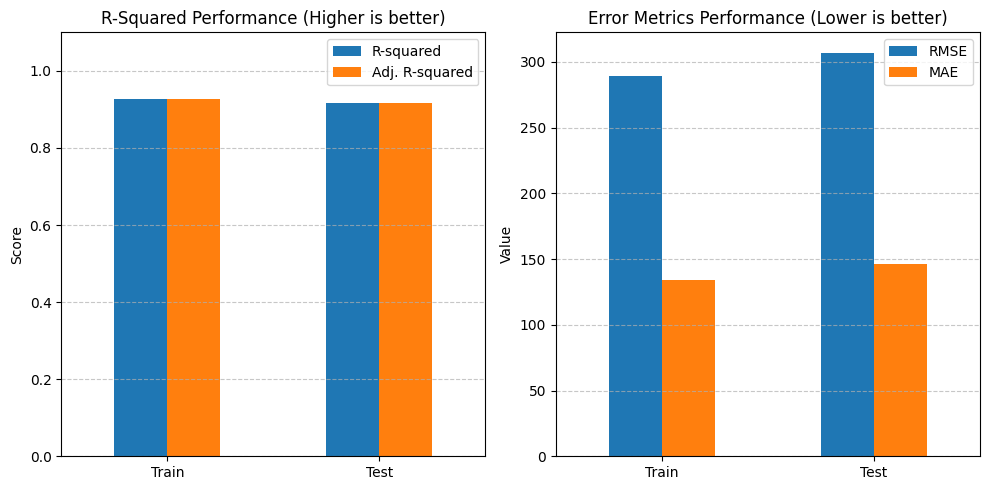

In [117]:
import matplotlib.pyplot as plt
import pandas as pd

# Combine performance metrics for plotting
perf_df = pd.concat([xgb_tuned_model_train_perf, xgb_tuned_model_test_perf], axis=0)
perf_df.index = ['Train', 'Test']

# Set up the figure and axes
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Plot R-Squared and Adjusted R-Squared (Higher is better)
perf_df[['R-squared', 'Adj. R-squared']].plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('R-Squared Performance (Higher is better)')
axes[0].set_ylabel('Score')
axes[0].set_ylim(0, 1.1)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot RMSE and MAE (Lower is better)
perf_df[['RMSE', 'MAE']].plot(kind='bar', ax=axes[1], rot=0)
axes[1].set_title('Error Metrics Performance (Lower is better)')
axes[1].set_ylabel('Value')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**OBSERVATIONS**:


---

- Based on the R-squared graph, we see consistent high performance in training and testing set, indicating a great model.
- The difference in the RMSE and MAE in training and testing set is not very high, meaning the model is generalizing well.

# **Model Performance Comparison, Final Model Selection, and Serialization**

### Training performance comparison

In [96]:
models_train_comp_df = pd.concat(
    [  rf_estimator_model_train_perf.T,
        xgb_estimator_model_train_perf.T,
        rf_tuned_model_train_perf.T,
        xgb_tuned_model_train_perf.T,], axis=1,)

models_train_comp_df.columns = ["Random Forest","XG Boost", "Random Forest Hyperparameter Tuned", "XGBoost Hyperparameter Tuned"]

print("Training performance comparison:")
models_train_comp_df


Training performance comparison:


,Random Forest,XG Boost,Random Forest Hyperparameter Tuned,XGBoost Hyperparameter Tuned
RMSE,107.291758,134.301331,343.081419,289.251317
MAE,40.409749,63.217520,231.276802,133.826254
R-squared,0.989849,0.984095,0.896208,0.926223
Adj. R-squared,0.989833,0.984070,0.896044,0.926107
MAPE,0.015157,0.022565,0.083812,0.052573


### Testing performance comparison

In [97]:
models_test_comp_df = pd.concat([
        rf_estimator_model_test_perf.T,
        xgb_estimator_model_test_perf.T,
        rf_tuned_model_test_perf.T,
        xgb_tuned_model_test_perf.T, ], axis=1,)

models_test_comp_df.columns = ["Random Forest","XG Boost", "Random Forest Hyperparameter Tuned", "XGBoost Hyperparameter Tuned"]

print("Testing performance comparison:")
models_test_comp_df

Testing performance comparison:


,Random Forest,XG Boost,Random Forest Hyperparameter Tuned,XGBoost Hyperparameter Tuned
RMSE,283.666994,303.665445,354.757564,307.180991
MAE,108.883377,134.648132,240.914464,146.124943
R-squared,0.929478,0.919184,0.889701,0.917302
Adj. R-squared,0.929032,0.918673,0.889004,0.916779
MAPE,0.038951,0.049395,0.086063,0.053490


**OBSERVATIONS**:


---

- We ran 4 regression models: Random Forest , XG Boost , Random Forest with Hyperparameter tuning, XG Boost with Hyperparameter tuning
- The explanation of choosing these is before starting Model building
- Since it is a regression model, we evaluated the performance of the model on training and testing set on following parameters: Root Mean Squared Error, Mean Absolute Error, R-squared, Adjusted R-squared, Mean Absolute percentage error.
- A good model should have R-squared ad Adjusted R-squared > 0.7. Ours is close to 0.9 in all 4!
- RMSE and MAE vary based on model but the lower the value, better the model.
- Also MAPE for our models are < 10% which is also a great indication
---
- Hence to choose the final model, we will compare the R-squared, Adjust R-squared, MAPE for training vs testing data to look for best performance with minimal overfitting and good generalization.(less difference in training and testing)
- Keeping these in mind and comparing the numbers from the previous 2 tables, we can choose: **XGBoost Hyperparameter tuned model** since the training and testing performance is similar to approx 0.926 and 0.917 for R-squared and similar for Adjusted R-squared respectively.
- Random Forest Tuned is also a back up model but XG Boost tuned has slightly higher score.
- The other 2 models are not generalising that well since the difference between trainign and testing performance is high.

### File Storage

In [98]:
# Create a folder for storing the files needed for web app deployment
os.makedirs("backend_files", exist_ok=True)

In [99]:
# Define the file path to save (serialize) the trained model along with the data preprocessing steps
saved_model_path = "backend_files/SuperKart_Sales_Prediction_Model_by_RC.joblib"

In [100]:
# Save the best trained model pipeline using joblib
joblib.dump(xgb_tuned, saved_model_path)

print(f"Model saved successfully at {saved_model_path}")

Model saved successfully at backend_files/SuperKart_Sales_Prediction_Model_by_RC.joblib


In [101]:
# Load the saved model pipeline from the file
saved_model = joblib.load("backend_files/SuperKart_Sales_Prediction_Model_by_RC.joblib")

# Confirm the model is loaded
print("Model loaded successfully.")

Model loaded successfully.


In [102]:
saved_model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('onehotencoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char']),
                                                 ('standardscaler',
                                                  StandardScaler(),
                                                  ['Product_Weight',
                                                   'Product_Allocated_Area',
                                                   'Product_M...
                              feature_types=None, gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=4, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=150, n_jobs=None,
                              num_parallel_tree=None, random_state=42, ...))])

In [103]:
# Let's try to make predictions on test set using deserialized model
saved_model.predict(X_test)

array([3455.4731, 3345.2515, 2475.7996, ..., 4180.7563, 2840.6736,
       4468.9893], dtype=float32)

**OBSERVATIONS**:


---
- We created a directory to save the backend files and the model. The model is named: SuperKart_Sales_Prediction_Model_by_RC. Then we loaded the model and sent a test predict() call to check if the model is predicting as expected.
- We had no issues there and hence the model can now be used to make predictions without any retraining


# **Deployment - Backend**

## Flask Web Framework


In [104]:
%%writefile backend_files/app.py

# Import necessary libraries
import numpy as np
import joblib  # For loading the serialized model
import pandas as pd  # For data manipulation
from flask import Flask, request, jsonify  # For creating the Flask API

# Initialize Flask app with a name
superkart_api = Flask("SuperKart Sales Predictor")
# Load the trained churn prediction model
model = joblib.load("SuperKart_Sales_Prediction_Model_by_RC.joblib")

# Define a route for the home page
@superkart_api.get('/')
def home():
    return "Welcome to the SuperKart Sales Predictor Application"

# Define an endpoint to predict churn for a single customer
@superkart_api.post('/v1/predict')
def predict_sales():
    # Get JSON data from the request
    data = request.get_json()

    # Extract relevant customer features from the input data. The order of the column names matters.
    sample = {
        'Product_Id_char': data['Product_Id_char'],
        'Product_Type': data['Product_Type'],
        'Product_Weight': data['Product_Weight'],
        'Product_Sugar_Content': data['Product_Sugar_Content'],
        'Product_Allocated_Area': data['Product_Allocated_Area'],
        'Product_MRP': data['Product_MRP'],
        'Store_Id': data['Store_Id'],
        'Store_Size': data['Store_Size'],
        'Store_Location_City_Type': data['Store_Location_City_Type'],
        'Store_Type': data['Store_Type'],
        'Store_Age_Years': data['Store_Age_Years']
    }

    # Convert the extracted data into a DataFrame
    input_data = pd.DataFrame([sample])

    # Make a churn prediction using the trained model
    prediction = model.predict(input_data).tolist()[0]

    # Return the prediction as a JSON response
    return jsonify({'Sales': prediction})


# Run the Flask app in debug mode
if __name__ == '__main__':
    superkart_api.run(debug=True)

Overwriting backend_files/app.py


**OBSERVATIONS**:


---
- Here we are creating our main backend application file: app.py using Flask Web Framework. It will take the values from the front end and run the model.predict() method on the sample input from the user and out put the predicted Sales value.

## Dependencies File

In [105]:
%%writefile backend_files/requirements.txt
pandas==2.2.2
numpy==2.0.2
scikit-learn==1.6.1
seaborn==0.13.2
joblib==1.4.2
xgboost==2.1.4
joblib==1.4.2
Werkzeug==2.2.2
flask==2.2.2
gunicorn==20.1.0
requests==2.32.3
uvicorn[standard]
streamlit==1.43.2

Overwriting backend_files/requirements.txt


**OBSERVATIONS**:


---
- Creating the dependencies file for back end.

## Dockerfile

In [106]:
%%writefile backend_files/Dockerfile
FROM python:3.9-slim

# Set the working directory inside the container
WORKDIR /app

# Copy all files from the current directory to the container's working directory
COPY . .

# Install dependencies from the requirements file without using cache to reduce image size
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Define the command to start the application using Gunicorn with 4 worker processes
# - `-w 4`: Uses 4 worker processes for handling requests
# - `-b 0.0.0.0:7860`: Binds the server to port 7860 on all network interfaces
# - `app:app`: Runs the Flask app (assuming `app.py` contains the Flask instance named `app`)
CMD ["gunicorn", "-w", "4", "-b", "0.0.0.0:7860", "app:superkart_api"]

Overwriting backend_files/Dockerfile


**OBSERVATIONS**:


---
- Creating the Docker file for back end.

## Setting up a Hugging Face Docker Space for the Backend

In [123]:
from huggingface_hub import login, create_repo
from google.colab import userdata

# Securely fetch token from Colab Secrets
login(token= userdata.get('access_key'))

In [124]:
# Try to create the repository for the Hugging Face Space
try:
    create_repo("SuperKart-Sales-Predictor-API",
        repo_type="space",
        space_sdk="docker",
        private=False
    )
except Exception as e:
    # Handle potential errors during repository creation
    if "RepositoryAlreadyExistsError" in str(e):
        print("Repository already exists. Skipping creation.")
    else:
        print(f"Error creating repository: {e}")

Error creating repository: 409 Client Error: Conflict for url: https://huggingface.co/api/repos/create (Request ID: Root=1-69925b73-66f3964f57a72feb1c7adbc3;8cbe5f36-dbb3-46b6-a7df-8c01ad9272b2)

You already created this space repo: riddhichavda/SuperKart-Sales-Predictor-API


**OBSERVATIONS**:


---
- First we created a directory for the backend_files which will include the Docker image file, requirements.txt and our FlaskWebFramework app file.
- Then we created a separate repository for Back End application called: SuperKart-Sales-Predictor-API and uploaded the files there.
- To connect to Hugging face, we used the access token. The access token value is stored under secrets on Colab and accessed from there.


## Uploading Files to Hugging Face Space (Docker Space)

In [125]:
# Fetch token and repo details
access_key = userdata.get('access_key')
repo_id = "riddhichavda/SuperKart-Sales-Predictor-API"

# Initialize the API
api = HfApi()

# Upload backend files
api.upload_folder(
    folder_path="/content/backend_files",
    repo_id=repo_id,
    repo_type="space",
)

Processing Files (0 / 0)                : |          |  0.00B /  0.00B            

New Data Upload                         : |          |  0.00B /  0.00B            

  ...Sales_Prediction_Model_by_RC.joblib: 100%|##########|  259kB /  259kB            

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/spaces/riddhichavda/SuperKart-Sales-Predictor-API/commit/4897a8816556d40093ba103a10e555f5b94370a5', commit_message='Upload folder using huggingface_hub', commit_description='', oid='4897a8816556d40093ba103a10e555f5b94370a5', pr_url=None, repo_url=RepoUrl('https://huggingface.co/spaces/riddhichavda/SuperKart-Sales-Predictor-API', endpoint='https://huggingface.co', repo_type='space', repo_id='riddhichavda/SuperKart-Sales-Predictor-API'), pr_revision=None, pr_num=None)

**OBSERVATIONS**:


---
- Now that we have all the back end files, we will upload them to Hugging Face Back End Repo: SuperKart-Sales-Predictor-API

# **Deployment - Frontend**

## Points to note before executing the below cells
- Create a Streamlit space on Hugging Face by following the instructions provided on the content page titled **`Creating Spaces and Adding Secrets in Hugging Face`** from Week 1

## Streamlit for Interactive UI

In [126]:
# Create a folder for storing the files needed for frontend UI deployment
os.makedirs("frontend_files", exist_ok=True)

In [127]:
# Try to create the Front End repository for the Hugging Face Space
try:
    create_repo("SuperKart-Sales-Predictor-App",
        repo_type="space",
        space_sdk="docker",
        private=False
    )
except Exception as e:
    # Handle potential errors during repository creation
    if "RepositoryAlreadyExistsError" in str(e):
        print("Repository already exists. Skipping creation.")
    else:
        print(f"Error creating repository: {e}")

Error creating repository: 409 Client Error: Conflict for url: https://huggingface.co/api/repos/create (Request ID: Root=1-69925b7e-217beacf73f55eea5f4afd65;315b79e1-e357-424d-ac77-39eed4c37072)

You already created this space repo: riddhichavda/SuperKart-Sales-Predictor-App


**OBSERVATIONS**:


---
- First we created a directory for the frontend_files which will include the Docker image, requirements.txt and our app file.
- Then we created a separate repository for Front End application called: SuperKart-Sales-Predictor-App
- The Error creating Rep can be ignored as the Notebook was run multiple times and we do not need to create the repo once created.  


In [128]:
%%writefile frontend_files/app.py

import streamlit as st
import requests

st.title("SuperKart Sales Predictor App")

# Input fields for product and store data
Product_Id_char = st.selectbox("Product ID Character", ["FD", "NC", "DR"])
Product_Type = st.selectbox("Product Type", ["Frozen Foods", "Dairy", "Canned", "Baking Goods",
       "Health and Hygiene", "Snack Foods", "Meat", "Household",
       "Hard Drinks", "Fruits and Vegetables", "Breads", "Soft Drinks",
       "Breakfast", "Others", "Starchy Foods", "Seafood"])
Product_Weight = st.number_input("Product Weight", min_value=0.0, value=12.66)
Product_Sugar_Content = st.selectbox("Product Sugar Content", ["Low Sugar", "Regular", "No Sugar"])
Product_Allocated_Area = st.number_input("Product Allocated Area", min_value=0.004, value=0.298)
Product_MRP = st.number_input("Product MRP", min_value=31.0, value=266.0)
Store_Id = st.selectbox("Store ID", ["OUT001", "OUT002", "OUT003", "OUT004"])
Store_Size = st.selectbox("Store Size", ["Small", "Medium", "High"])
Store_Location_City_Type = st.selectbox("Store Location City Type", ["Tier 1", "Tier 2", "Tier 3"])
Store_Type = st.selectbox("Store Type", ["Food Mart", "Departmental Store", "Supermarket Type1", "Supermarket Type2"])
Store_Age_Years = st.number_input("Store Age (Years)", min_value=0, value=16)

# Map widget variables to the payload dictionary
product_data = {
        'Product_Id_char': Product_Id_char,
        'Product_Type': Product_Type,
        'Product_Weight': Product_Weight,
        'Product_Sugar_Content': Product_Sugar_Content,
        'Product_Allocated_Area': Product_Allocated_Area,
        'Product_MRP': Product_MRP,
        'Store_Id': Store_Id,
        'Store_Size': Store_Size,
        'Store_Location_City_Type': Store_Location_City_Type,
        'Store_Type': Store_Type,
        'Store_Age_Years': Store_Age_Years
}

if st.button("Predict", type='primary'):
    # Using the deployment URL provided in your logic
    response = requests.post("https://riddhichavda-superkart-sales-predictor-api.hf.space/v1/predict", json=product_data)
    if response.status_code == 200:
        result = response.json()
        predicted_sales = result["Sales"]
        st.write(f"Predicted Product Store Sales Total: ₹{predicted_sales:.2f}")
    else:
        st.error("Error in API request")

Overwriting frontend_files/app.py


**OBSERVATIONS**:


---
- This is our main front end application file which will act like a form to input different values for the features that we trained our model on. These features are the same our models as well as what we configured in the backend files.
- We added a Predict button which will predict the sales. (Note: the default currency was set to Rupee as per low code so have retained that. But need to verify that.)
- REsponse code 200 will indicate success where as for other codes, error handling is done by showing the error message.

## Dependencies File

In [129]:
%%writefile frontend_files/requirements.txt
requests==2.32.3
streamlit==1.45.0

Overwriting frontend_files/requirements.txt


**OBSERVATIONS**:


---
- Creating the dependencies file for front end.

## DockerFile

In [130]:
%%writefile frontend_files/Dockerfile
# Use a minimal base image with Python 3.9 installed
FROM python:3.9-slim

# Set the working directory inside the container to /app
WORKDIR /app

# Copy all files from the current directory on the host to the container's /app directory
COPY . .

# Install Python dependencies listed in requirements.txt
RUN pip3 install -r requirements.txt

# Define the command to run the Streamlit app on port 7860 and make it accessible externally
CMD ["streamlit", "run", "app.py", "--server.port=7860", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false"]

# NOTE: Disable XSRF protection for easier external access in order to make batch predictions

Overwriting frontend_files/Dockerfile


**OBSERVATIONS**:


---
- Creating the Docker image file for front end. The port was configured to match the backend

## Uploading Files to Hugging Face Space (Streamlit Space)

In [133]:
# Fetch token and repo details
access_key = userdata.get('access_key')
repo_id = "riddhichavda/SuperKart-Sales-Predictor-App"

# Initialize the API
api = HfApi()

# Upload frontend files
api.upload_folder(
    folder_path="frontend_files",
    repo_id=repo_id,
    repo_type="space",
)

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/spaces/riddhichavda/SuperKart-Sales-Predictor-App/commit/7c48318eadb79f96ecde9ffd999522f9995368ce', commit_message='Upload folder using huggingface_hub', commit_description='', oid='7c48318eadb79f96ecde9ffd999522f9995368ce', pr_url=None, repo_url=RepoUrl('https://huggingface.co/spaces/riddhichavda/SuperKart-Sales-Predictor-App', endpoint='https://huggingface.co', repo_type='space', repo_id='riddhichavda/SuperKart-Sales-Predictor-App'), pr_revision=None, pr_num=None)

**OBSERVATIONS**:


---
- Now that we have all files, we will upload them to Hugging Face Front End Repo: SuperKart-Sales-Predictor-App

**RESULTS**:



---

- [Sales Predictor App Link](https://huggingface.co/spaces/riddhichavda/SuperKart-Sales-Predictor-App)
- Screenshot : 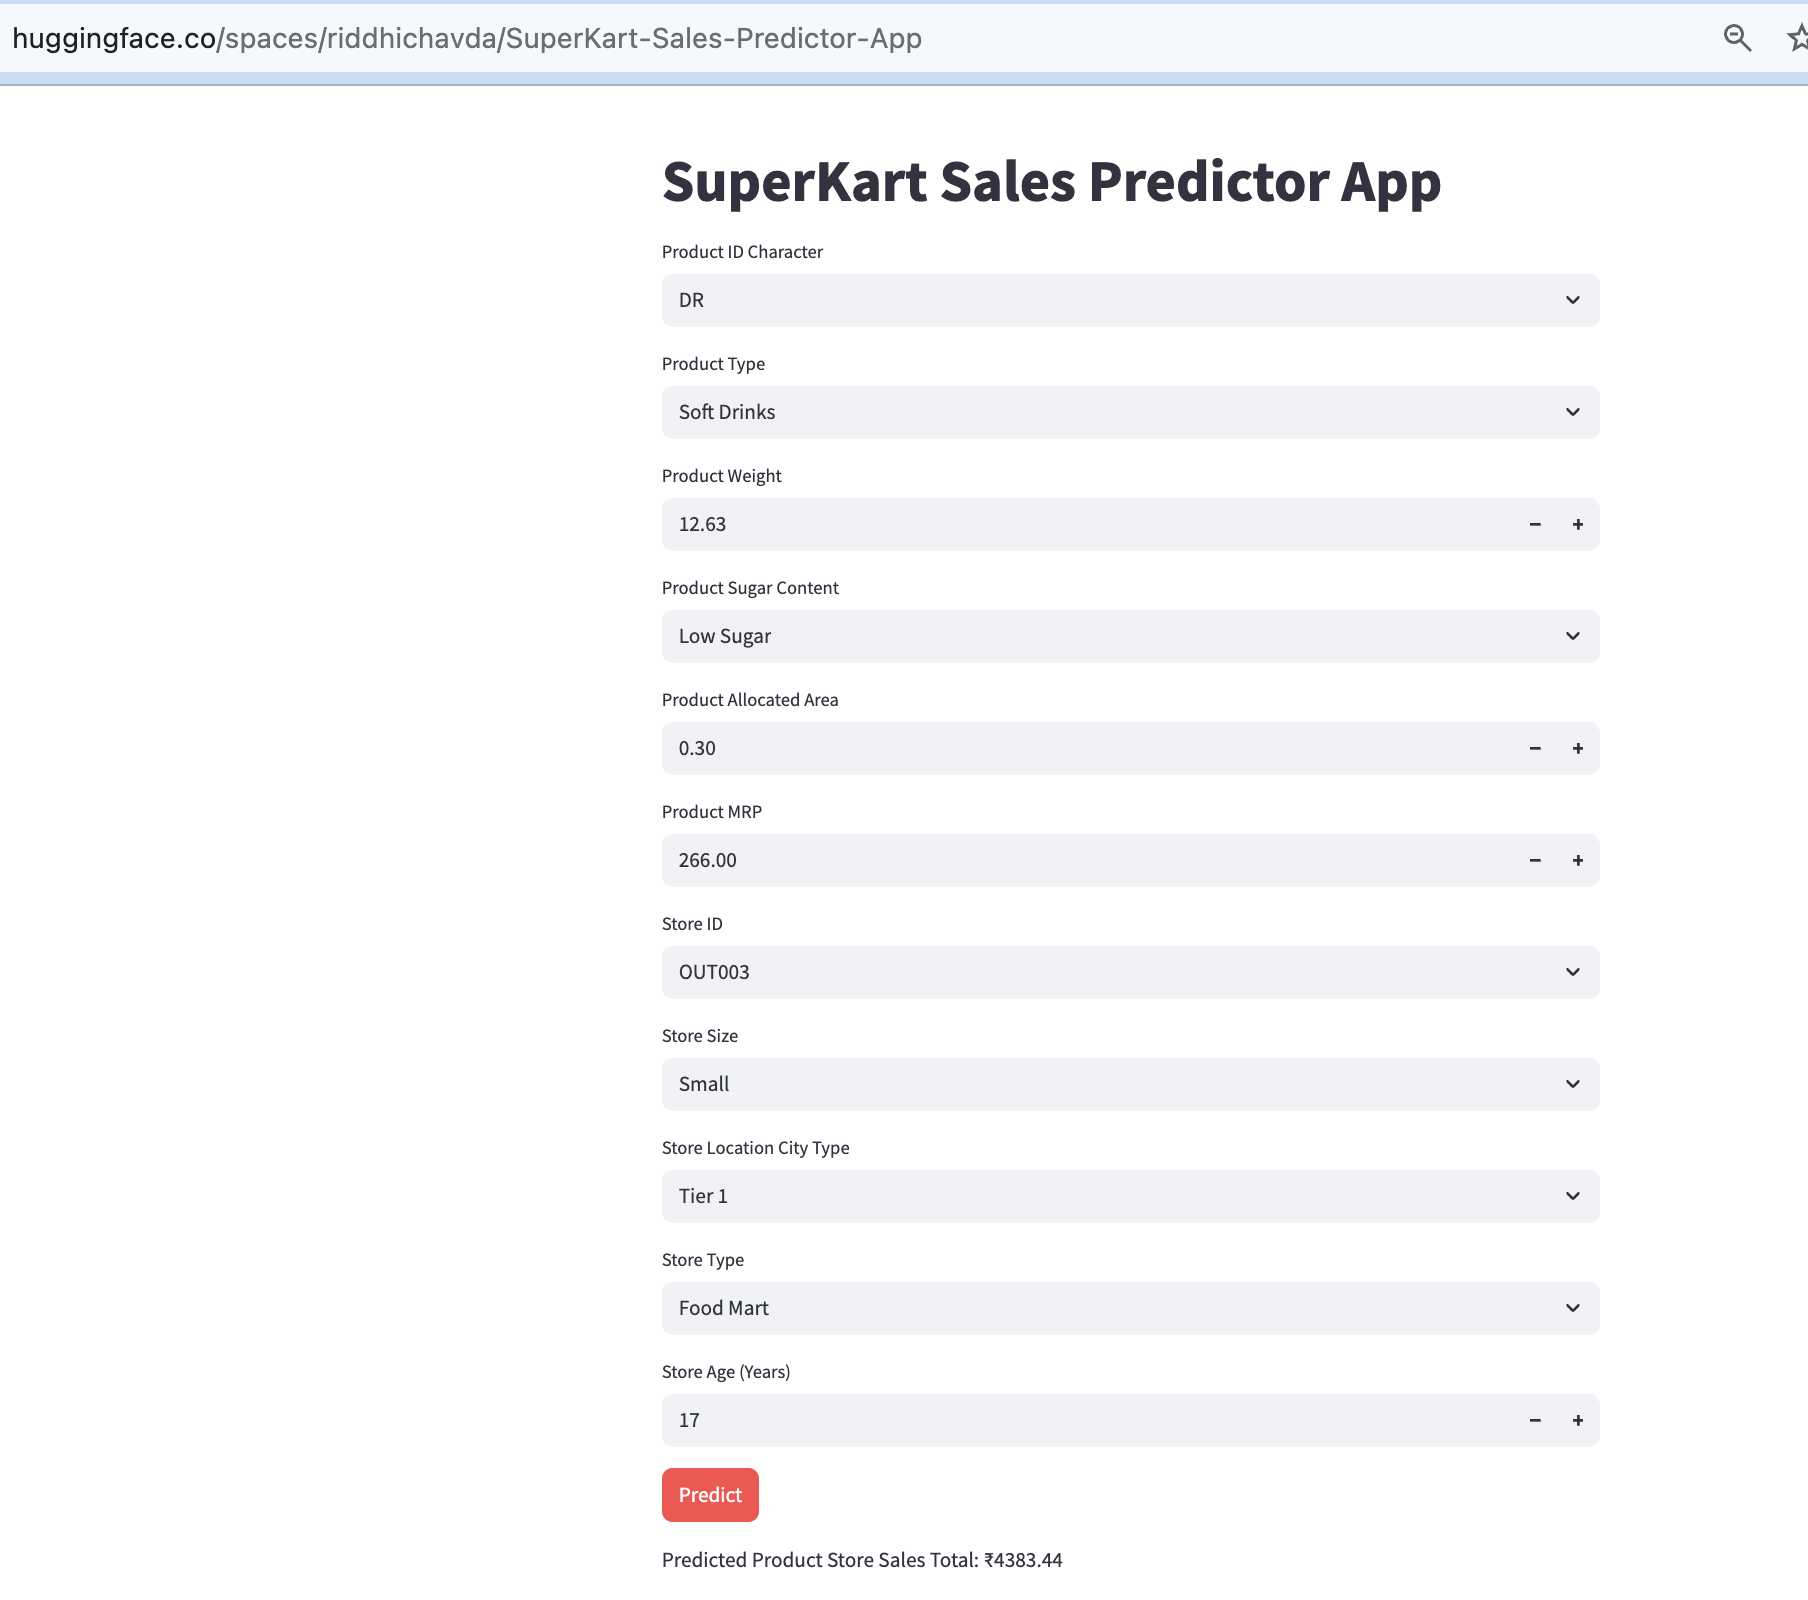

# **Actionable Insights and Business Recommendations**


---

- **On the dataset:**
- We had a limited dataset of ~8800 records and data from 4 stores. To have a better model, we should try to train our model on a **larger dataset** from possibly more data
- For our main target variable: Product_Store_Sales_Total, it was not clear for what period is this sales data for. We should probably get more insights into the same as it will also help us **evaluate Sales by quarter/month/year etc.**
- Currently we used 2 models for training but we should **periodically train our model** and update it to keep improving the performance based on latest changes. In a consumer market, the prices, customer spending, trends keep changing. So if we do not update our model regularly, the data would become stale and the model performance would not be as efficient or accurate.
- We can even **add feature importance** for certain features to improve our model, expermisment further with changing parameters and learning_rate.
- The deployed model can have an app version, have **improved integrated UI**.
- Probably even add a future feature for users to **file upload quarterly Sales Reports** in our dataset format **for further training** and updating models.


- **Analyse and update:**
- We did quite a bit of feature relationship analysis through our combinations of univariant and bivariant graphs of different types, but this would give more hidden insightful data, as to which stores has less spending but more customers, generating more revenue.
- We can adjust multiple parameters based on our analysis to improve sales like which products of which ranges and which Sugar content to increase based on the demographic of Consumers.
- For example, if Tier 2 cities spend more on Fruits and Vegetables, and on lower MRP products, those products should be stocked more for such stores.
- By regular updates, we could even **analyse the trends on Sales for newer items** and how they fare **for different cities, stores**, etc.
- By having quarterly or monthly Sales report, we could even estimate **which products sell better in which month** and can stock up accordingly.
- For example, chocolates and flowers might be selling more during Valentine's day, Baking goods more during festive months, Fruits and Vegetables more during January due to new year resolutions, etc.


